# Instalar os programas e montar o google Drive

In [ ]:
!pip install pyabf
!pip install efel

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


INFORMAR O CAMINHO PARA A PASTA ONDE ESTAO OS ARQUIVOS A SEREM ANALISADOS:


 OBS.: recomendo deixar este arquivo_de_codigo no msm local da pasta dos arquivos

In [ ]:
# '/content/drive/Shareddrives/SAMP-8 e SAMR-1/Registros Eletrofisiológicos'/ # folder antigo

In [ ]:
cd '/content/drive/MyDrive/Laboratorio Neurofisiologia/Projeto SAMP8/Registros Eletrofisiológicos'

/content/drive/.shortcut-targets-by-id/1lMJs6OOxMh_gEFC-2der6SB0a4NRFsG3/Laboratorio Neurofisiologia/Projeto SAMP8/Registros Eletrofisiológicos


Para verificar se o local esta correto:

In [ ]:
ls -li

total 23595
84 drwx------ 8 root root     4096 Aug 15  2024 '50-70 dias de idade SAMP-8 controle'/
88 drwx------ 9 root root     4096 Aug 16  2024 '7-8 meses de idade'/
89 -rw------- 1 root root  2178387 May  9  2025  ANALISES_ATIVAS_2025.ipynb
83 -rw------- 1 root root   752606 Mar 22 14:22  ANALISES_felipe_ATIVAS_3spikes_first_after_REO.ipynb
91 -rw------- 1 root root   700255 May 27  2025  ANALISES_FERNANDO_ATIVAS_3spikes_2nd_after_Reo.ipynb
96 -rw------- 1 root root  6720171 Mar 20 03:17  ANALISES_FERNANDO_ATIVAS_3spikes_first_after_REO.ipynb
98 -rw------- 1 root root   667592 Mar 22 13:48  ANALISES_modified_ATIVAS_2026_SAMP_3spikes.ipynb
92 -rw------- 1 root root 10899096 May 27  2025  ANALISES_PASSIVAS_2025_fernando.ipynb
94 -rw------- 1 root root  1540596 Mar 10 20:27  ANALISES_PASSIVAS_2026_Fernando.ipynb
95 -rw------- 1 root root    17283 Mar 20 02:57 'Cópia de RAMP_SAMP_old.xlsx'
87 -rw------- 1 root root   119451 Aug 15  2024 'CPF SAMP x SAMR.pzfx'
97 -rw------- 1 root root

In [ ]:
import os
import efel
import pyabf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import DataFrame, Series

# SAMP8: 2 meses

In [ ]:
# Definir as pastas principais para análise
fldrs_principais = ['50-70 dias de idade SAMP-8 controle']

# Definir pastas a serem EXCLUÍDAS (nomes das pastas ou partes do caminho)
pastas_incluidas = ['HPC - CPT-8',
                      'Cell HPC',
                      'Agonista A2a - CGS21680',
                      '100 Hz',
                      '10 Hz',
                      '50 Hz']

# Definir nome do protocolo de interesse
protocolo = "Long"

times = []
voltages = []
I = []
cellnames = []
groupnames = []
full_folder_paths = []

Interneurons = []
ListaPaTCH = []

ListaFiles = []

ii = 0
for pasta_principal in pastas_incluidas:
  grupo = '50-70 dias de idade SAMP-8 controle/' + pasta_principal
  cellnumber = 0
  for cell in [fldrcell for fldrcell in sorted(os.listdir(grupo)) if '.' not in fldrcell]:
    for filename in sorted(os.listdir(grupo+'/'+cell))[0:3]:

      caminho_arquivo = grupo+'/'+cell+'/'+filename

      if 'Cell' in cell and grupo+'/'+cell not in ListaPaTCH:
                    try:
                        # print(f"Analisando: {caminho_arquivo}")
                        fileSize = os.path.getsize(caminho_arquivo)
                        if fileSize < 5000000:
                          abf = pyabf.ABF(caminho_arquivo)
                          if protocolo in abf.protocol and len(abf.sweepList) > 14  and "OLD" not in abf.protocol:
                              ii = ii + 1
                              print(f"{ii}, Analisando: {caminho_arquivo}, Protocolo: {abf.protocol}, Len SweepList: {len(abf.sweepList)}")
                              ListaPaTCH.append(grupo+'/'+cell)
                              ListaFiles.append(caminho_arquivo)
                    except:
                      pass


1, Analisando: 50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 01 - Incomplete/24523000.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
2, Analisando: 50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 02/24523015.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
3, Analisando: 50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 03/24523018.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
4, Analisando: 50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 04 - Incomplete/24919011.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 25
5, Analisando: 50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 05/24n21001.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 30
6, Analisando: 50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 06/24n21017.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
7, Anali

# SAMP8: 7-8 meses

In [ ]:
# Definir as pastas principais para análise
fldrs_principais = ['7-8 meses de idade']  # , '50-70 dias de idade SAMP-8 controle'

# Definir pastas a serem EXCLUÍDAS (nomes das pastas ou partes do caminho)
pastas_incluidas = ['SAMP-8_controle_adoR antag/CPT-8 100 nM', 'Agon. A2Ar 60nM', 'HPC whole cell/SAMP-8', '10 Hz - 50 pulses', '100 Hz - 50 pulses', '50 Hz/Controle']

# Definir nome do protocolo de interesse
protocolo = "Long"

times = []
voltages = []
I = []
cellnames = []
groupnames = []
full_folder_paths = []

Interneurons = []

ListaPaTCH = []

ii = 0
for pasta_principal in pastas_incluidas:
  grupo = '7-8 meses de idade/' + pasta_principal
  cellnumber = 0
  for cell in [fldrcell for fldrcell in sorted(os.listdir(grupo)) if '.' not in fldrcell]:
    for filename in sorted(os.listdir(grupo+'/'+cell))[0:3]:

      caminho_arquivo = grupo+'/'+cell+'/'+filename

      if 'Cell' in cell and grupo+'/'+cell not in ListaPaTCH:
                    try:
                        # print(f"Analisando: {caminho_arquivo}")
                        fileSize = os.path.getsize(caminho_arquivo)
                        if fileSize < 5000000:
                          abf = pyabf.ABF(caminho_arquivo)
                          if protocolo in abf.protocol and len(abf.sweepList) > 14  and "OLD" not in abf.protocol:
                              ii = ii + 1
                              print(f"{ii}, Analisando: {caminho_arquivo}, Protocolo: {abf.protocol}, Len SweepList: {len(abf.sweepList)}")
                              ListaPaTCH.append(grupo+'/'+cell)
                              ListaFiles.append(caminho_arquivo)
                    except:
                      pass


1, Analisando: 7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 01 - 500nM/24311000.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
2, Analisando: 7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 02 - 500 nM/24311012.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
3, Analisando: 7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 03 - 500nM/24311027.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
4, Analisando: 7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 04 - 100nM/24315037.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
5, Analisando: 7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 05 - 100 nM/24315048.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
6, Analisando: 7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 06 - 100nM/24318000

# SAMP8: 7-8 meses Cafeina

In [ ]:
# Definir as pastas principais para análise
fldrs_principais = ['7-8 meses de idade/Cafeina']  # , '50-70 dias de idade SAMP-8 controle'

# Definir pastas a serem EXCLUÍDAS (nomes das pastas ou partes do caminho)
pastas_incluidas = ['ZM - Antag. A2AR',
                      'Agon. A2Ar 60nM',
                      'Antag. A1R 100nM',
                      '50 Hz',
                      'Patch HPC',
                      '10 Hz',
                      '100 Hz']

# Definir nome do protocolo de interesse
protocolo = "Long"

times = []
voltages = []
I = []
cellnames = []
groupnames = []
full_folder_paths = []

Interneurons = []

ListaPaTCH = []


ii = 0
for pasta_principal in pastas_incluidas:
  grupo = '7-8 meses de idade/Cafeina/' + pasta_principal
  cellnumber = 0
  for cell in [fldrcell for fldrcell in sorted(os.listdir(grupo)) if '.' not in fldrcell]:
    for filename in sorted(os.listdir(grupo+'/'+cell))[0:3]:

      caminho_arquivo = grupo+'/'+cell+'/'+filename

      if 'Cell' in cell and grupo+'/'+cell not in ListaPaTCH:
                    try:
                        # print(f"Analisando: {caminho_arquivo}")
                        fileSize = os.path.getsize(caminho_arquivo)
                        if fileSize < 5000000:
                          abf = pyabf.ABF(caminho_arquivo)
                          if protocolo in abf.protocol and len(abf.sweepList) > 14  and "OLD" not in abf.protocol:
                              ii = ii + 1
                              print(f"{ii}, Analisando: {caminho_arquivo}, Protocolo: {abf.protocol}, Len SweepList: {len(abf.sweepList)}")
                              ListaPaTCH.append(grupo+'/'+cell)
                              ListaFiles.append(caminho_arquivo)
                    except:
                      pass


1, Analisando: 7-8 meses de idade/Cafeina/ZM - Antag. A2AR/Cell 01/24403022.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 26
2, Analisando: 7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 01/24525030.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 23
3, Analisando: 7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 02/24606000.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
4, Analisando: 7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 03/24607002.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 25
5, Analisando: 7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 04/24607010.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
6, Analisando: 7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 05/24608009.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
7, Analisando: 7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 

# Load all cells

In [ ]:
len(ListaFiles)

229

In [ ]:
import os
import efel
import pyabf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import DataFrame, Series
from scipy.signal import find_peaks
import seaborn as sns
import scipy.stats as stats


50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 01 - Incomplete/24523000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


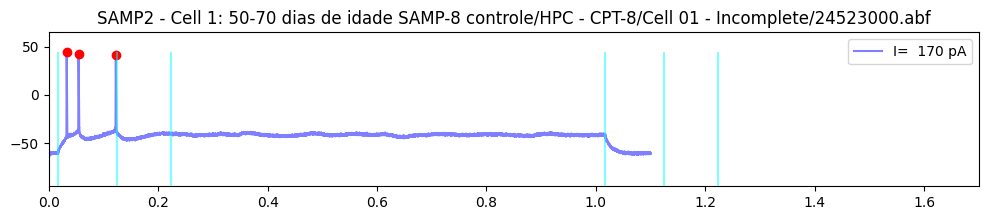

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 02/24523015.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


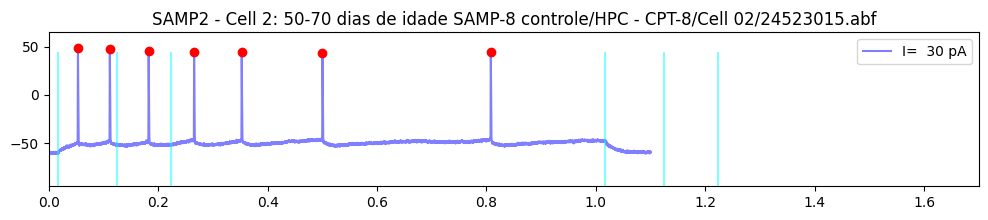

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 03/24523018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


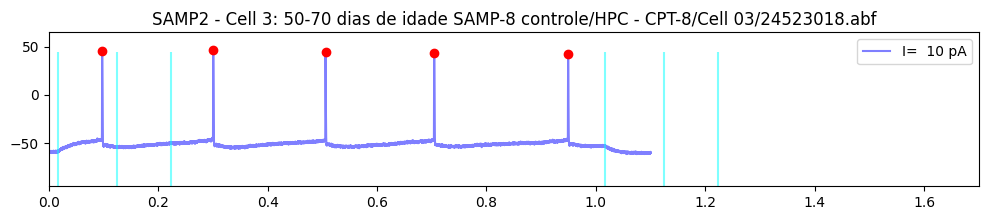

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 04 - Incomplete/24919011.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


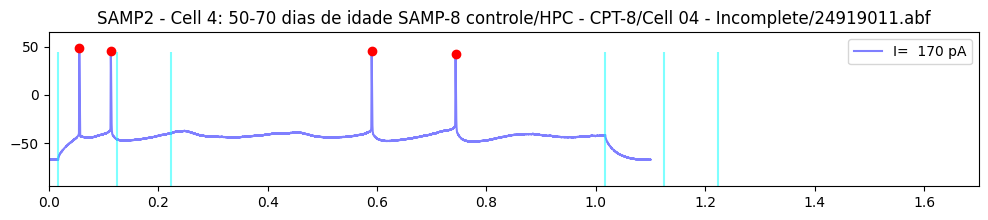

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 05/24n21001.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 06/24n21017.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


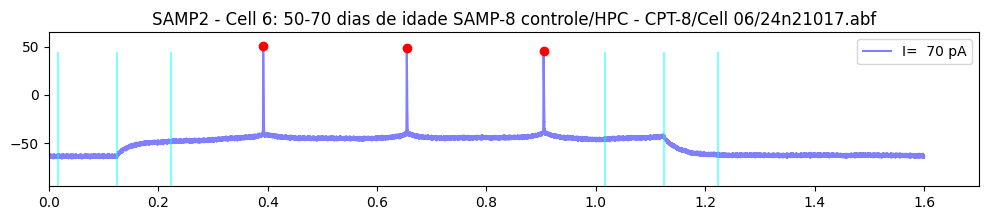

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 07/24n21013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 08/25415031.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


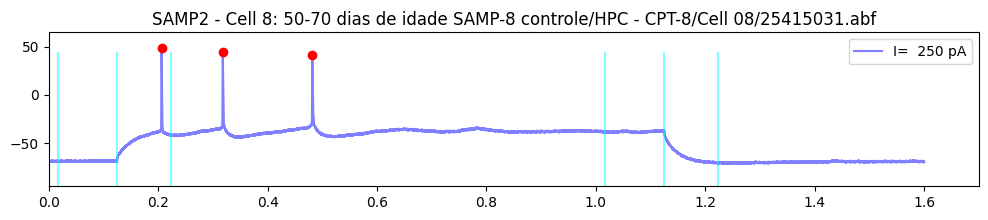

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 09 - PA outlier/25417030.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]


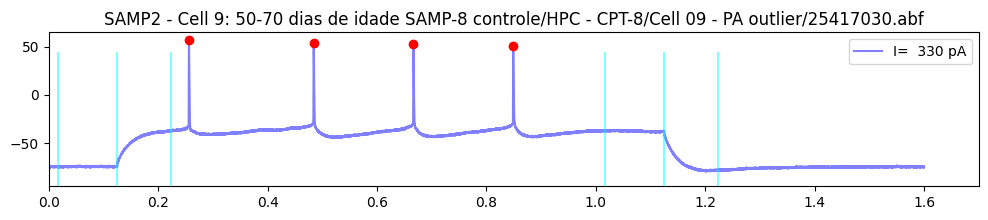

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 10 /25418000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


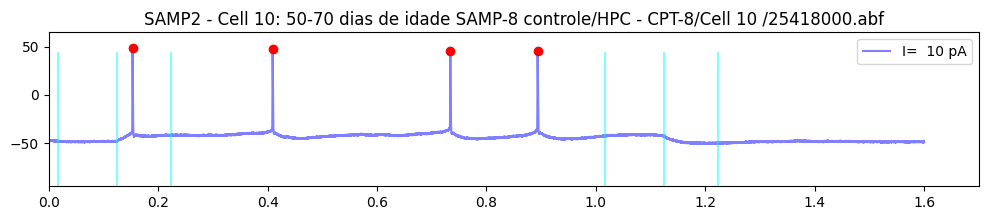

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 09/23516000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 10/23516014.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


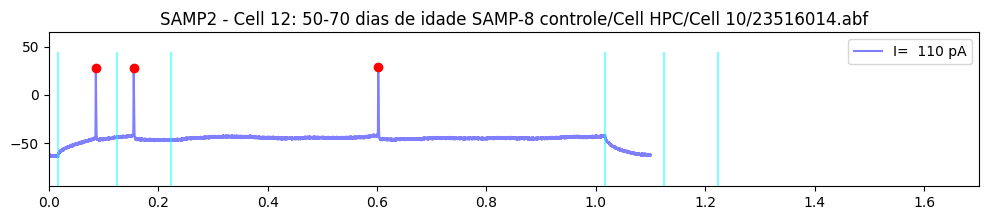

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 11/23517020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


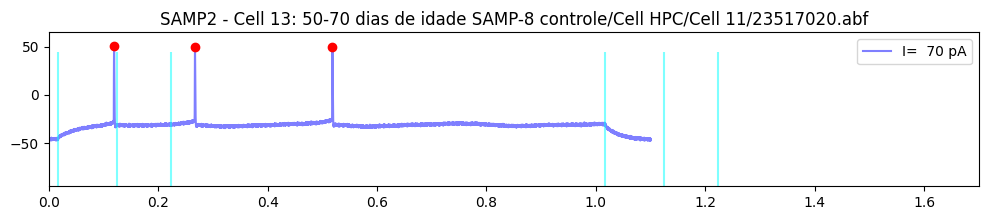

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 12/23519020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


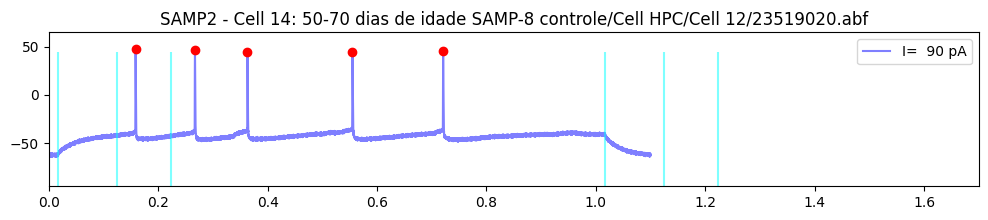

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 13/23519034.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


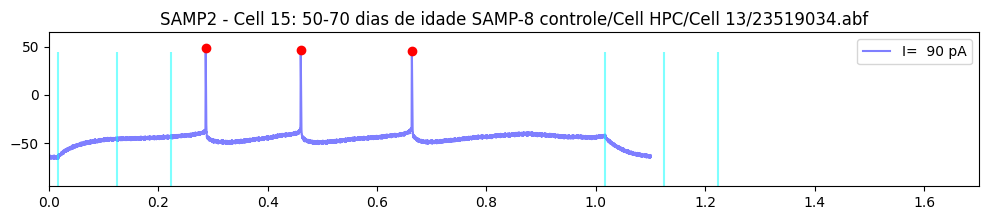

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 14/23520019.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


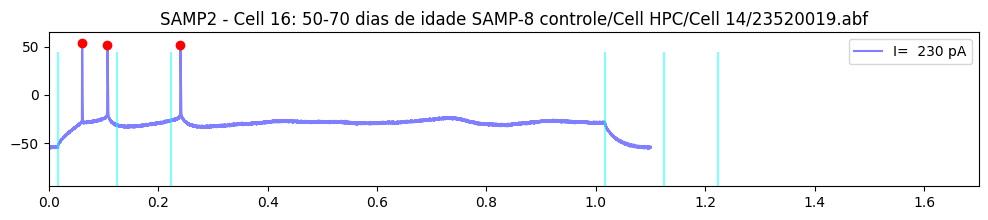

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 15/23520046 (1).abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


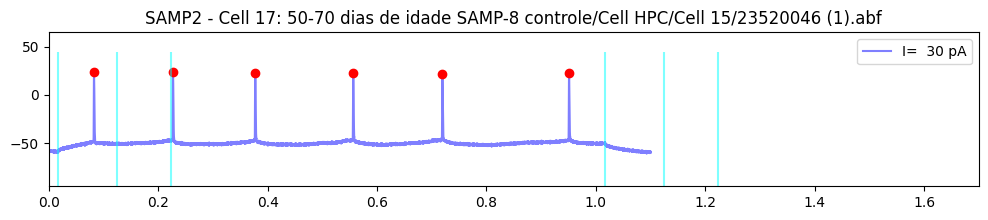

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 16/24523024.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


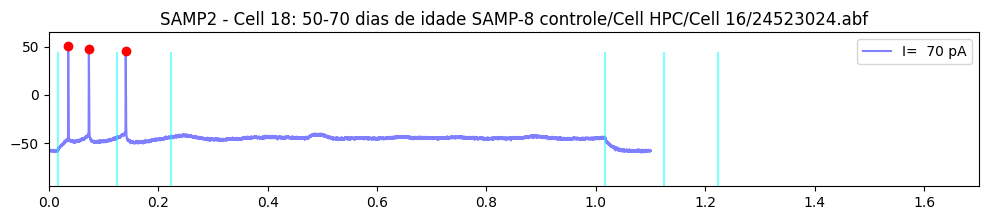

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 17/24523030.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


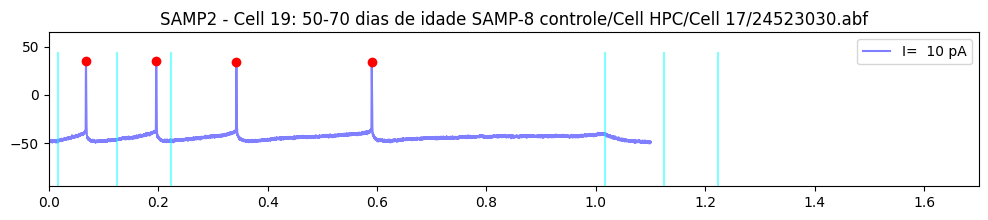

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 18/24528011.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


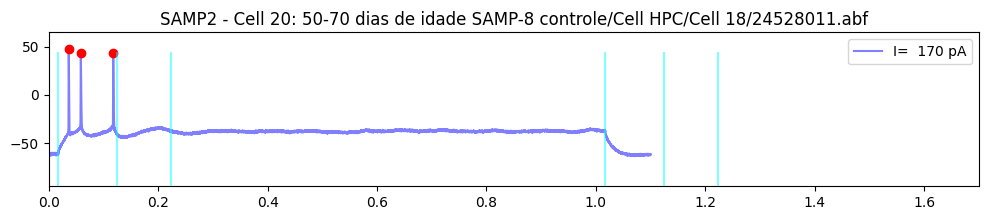

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 19/24919011.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


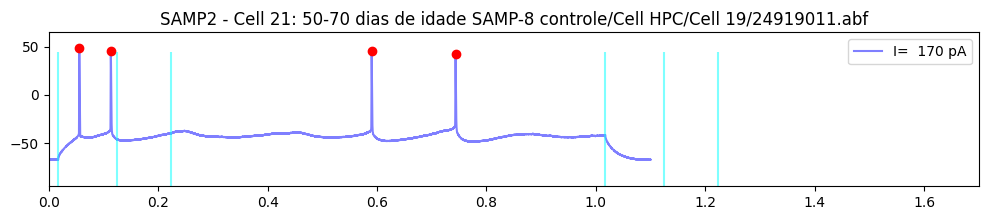

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 20/25616000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


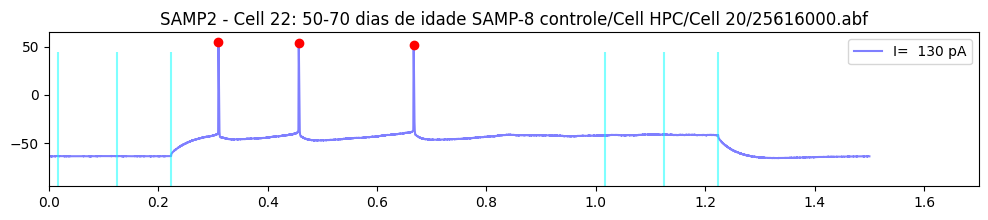

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 21/25617000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


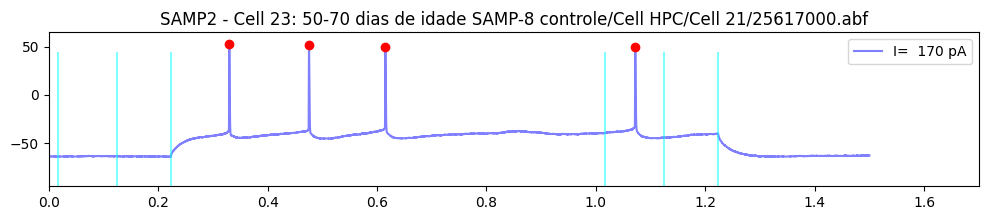

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 22/25616015.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


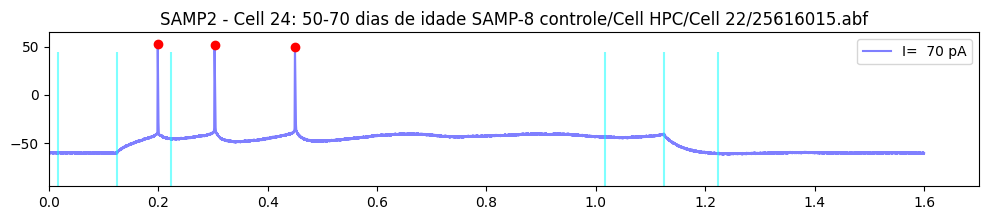

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 23/25616032.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


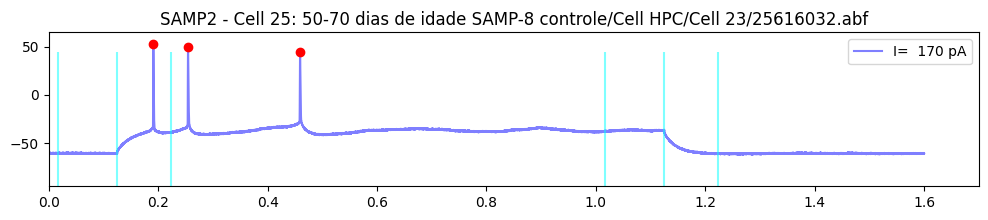

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 24/25617000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


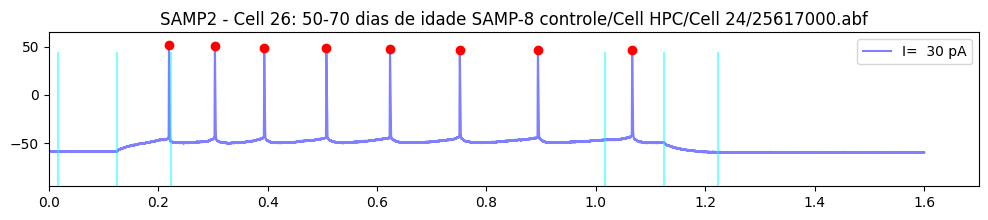

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 25/25617016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


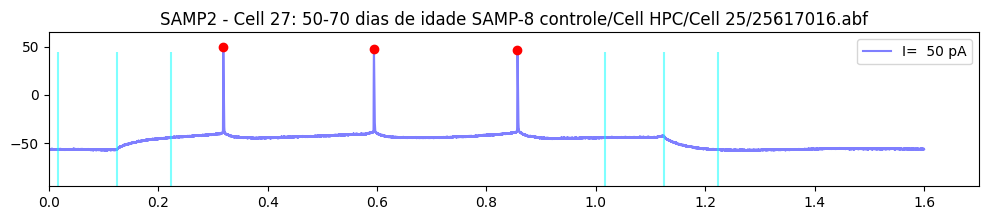

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 26/25617032.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


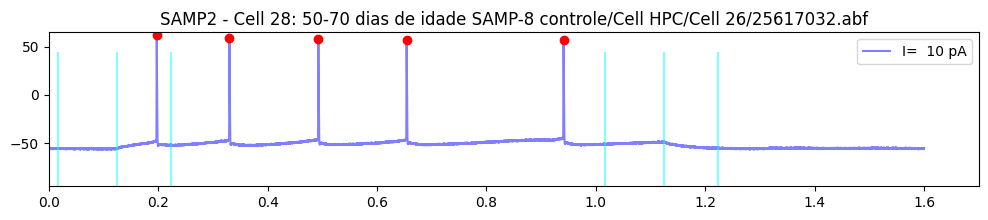

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 27/25617051.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


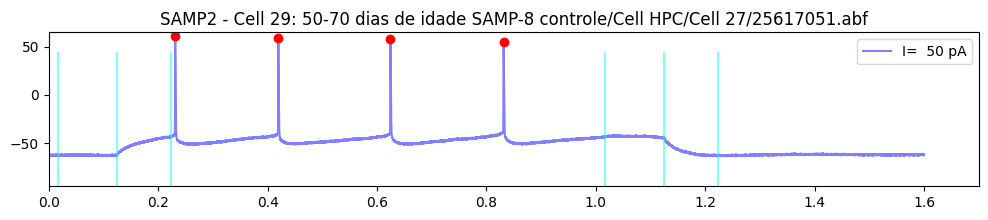

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 28/25617066.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


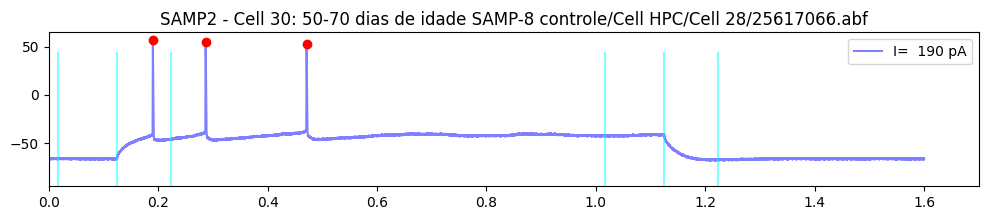

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 29/25617082.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


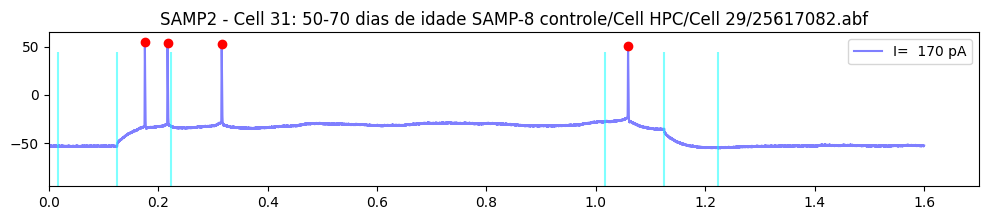

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 30/26305000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


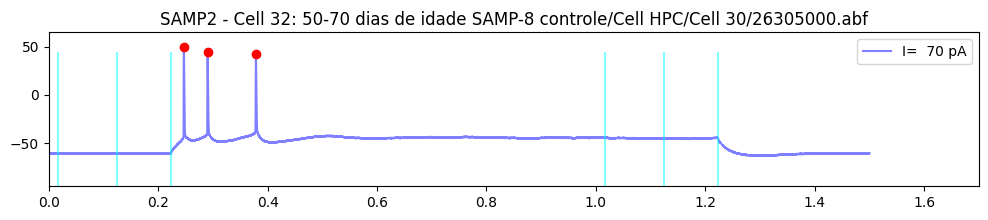

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 31/26305008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


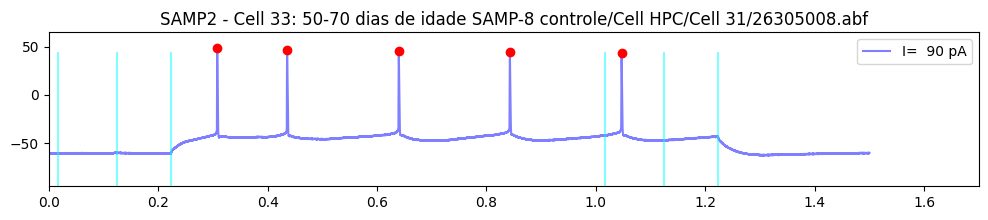

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 32/26305019.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


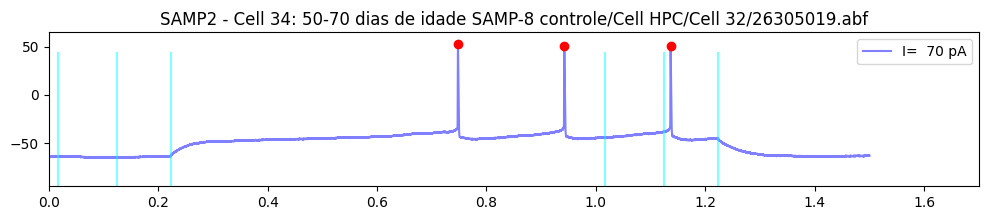

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 33/26305032.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


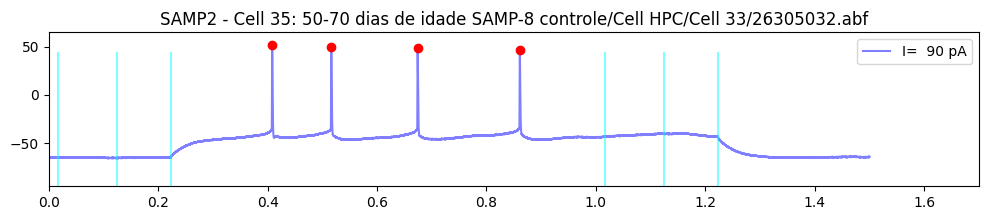

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 01/24919027.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


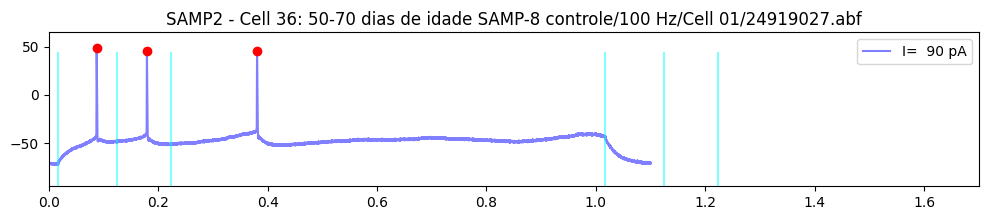

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 02/25311040.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


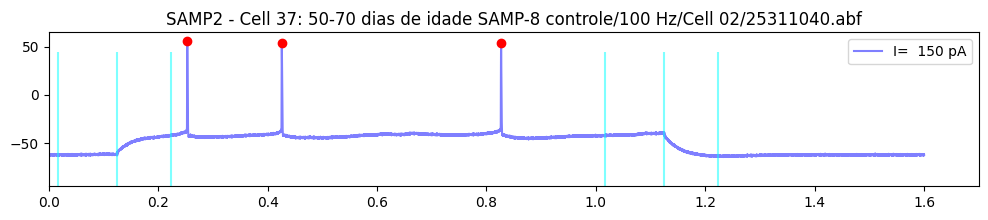

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 03 /25414002.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


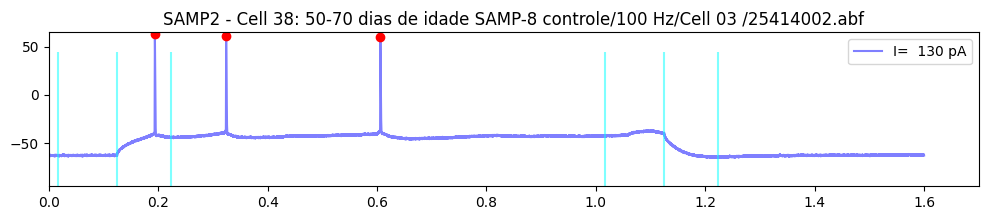

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 04/25415011.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


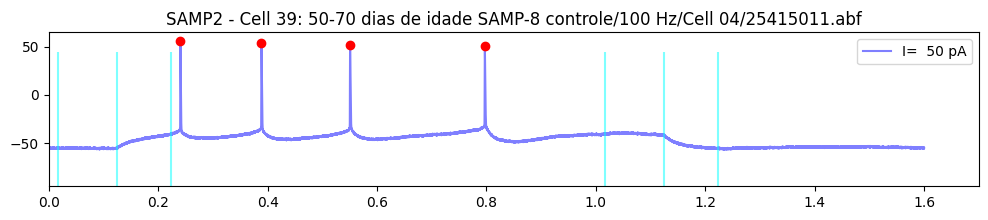

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 05/25415021.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


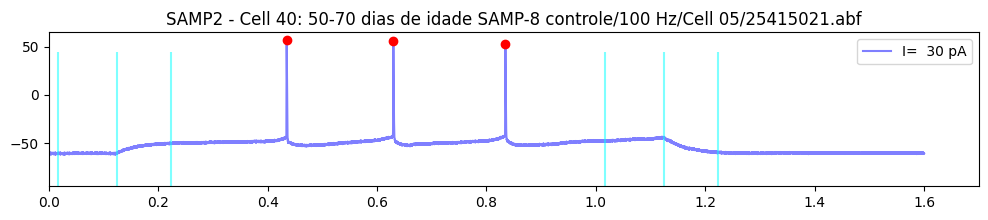

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 06 - PA outlier/25417010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


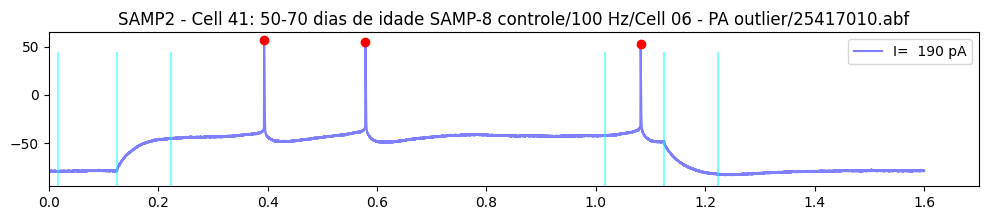

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 07 - PA outlier/25417020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


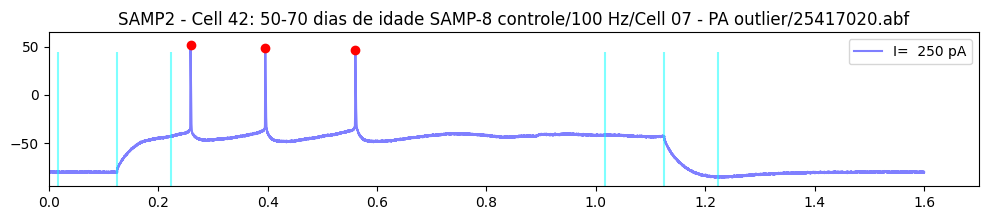

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 08/25422000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


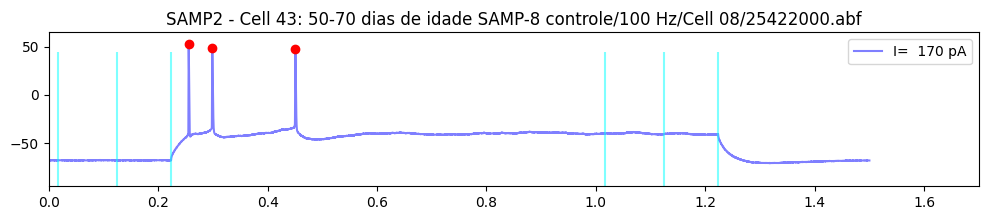

50-70 dias de idade SAMP-8 controle/10 Hz/Cell 01/24919015.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


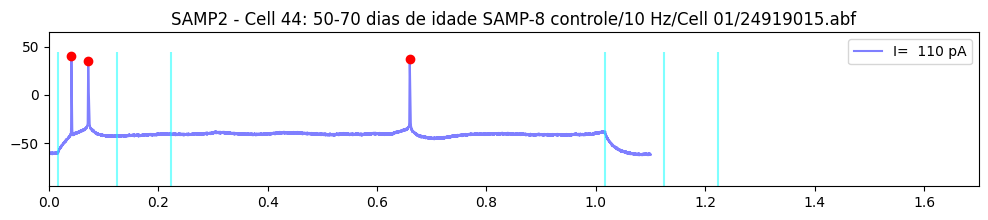

50-70 dias de idade SAMP-8 controle/10 Hz/Cell 03/25311019.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


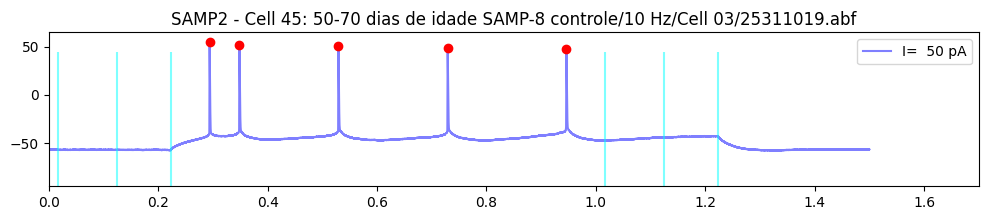

50-70 dias de idade SAMP-8 controle/10 Hz/Cell 05/25415036.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


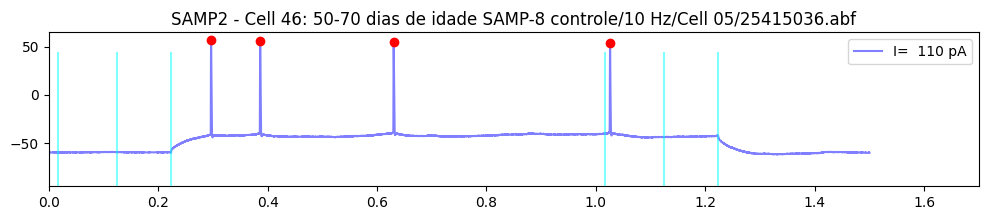

50-70 dias de idade SAMP-8 controle/10 Hz/Cell 06/25417030.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


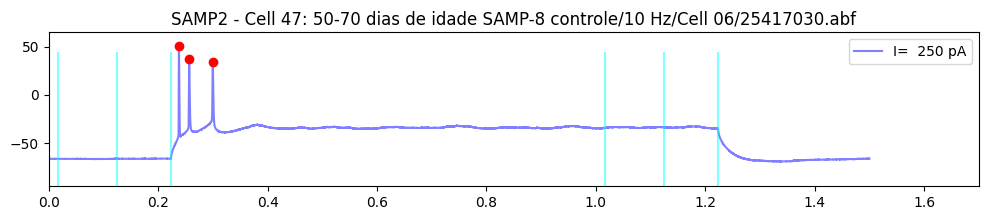

50-70 dias de idade SAMP-8 controle/10 Hz/Cell 07/25418128.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


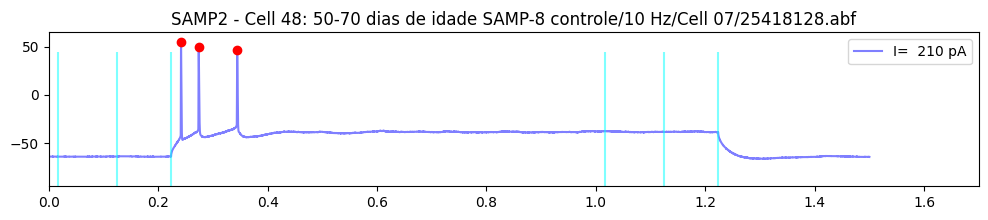

50-70 dias de idade SAMP-8 controle/10 Hz/Cell 08/25422004.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


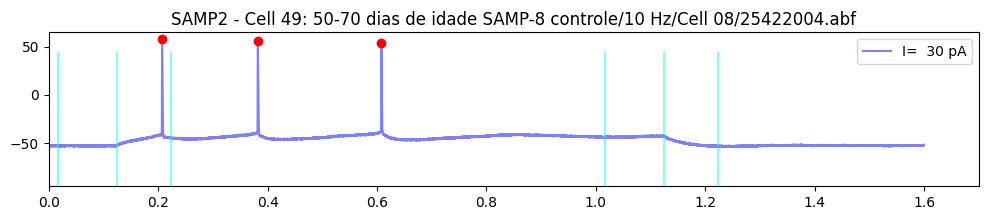

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 01/24523008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


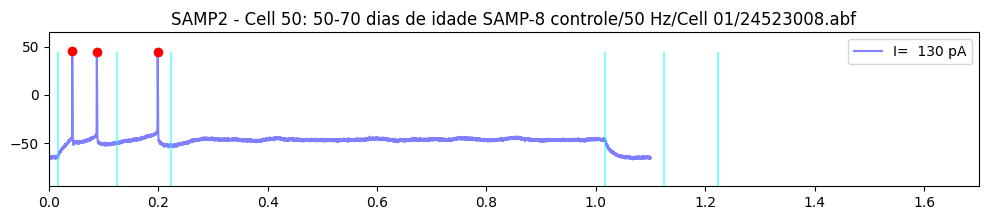

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 02/24523038.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


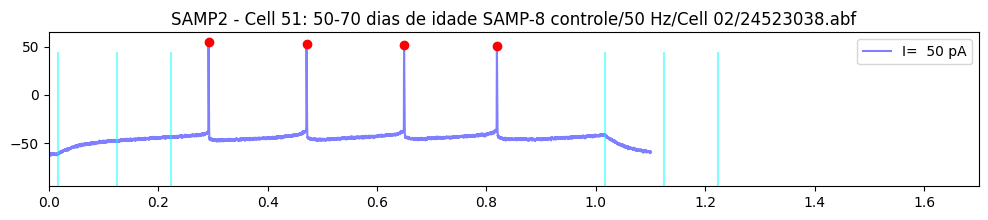

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 03 - Incomplete/24528000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


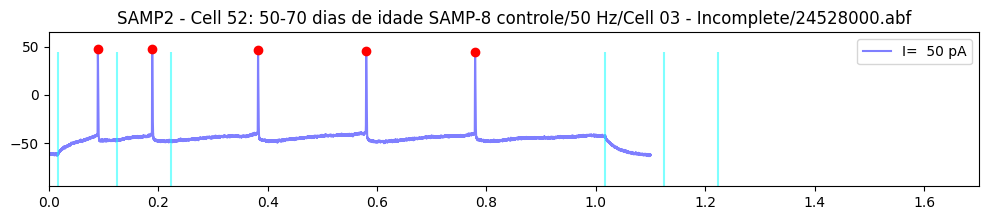

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 04/24528016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


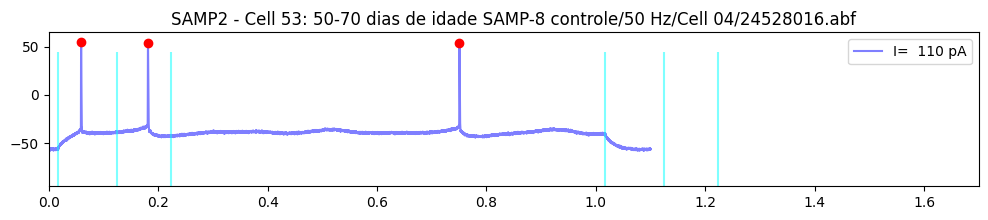

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 05/24919006.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


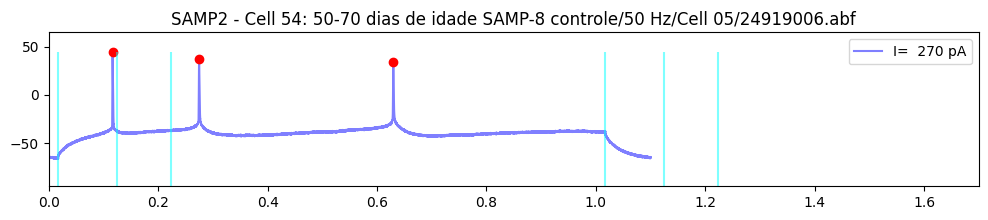

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 06/24n21007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


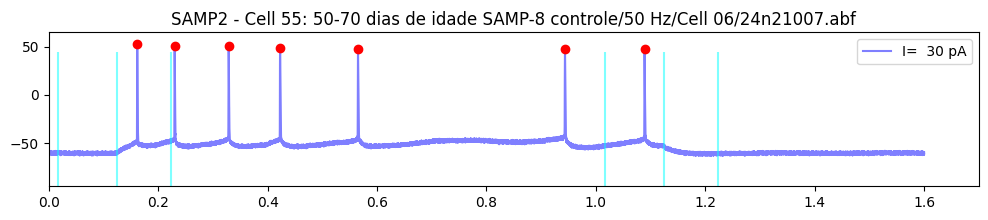

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 07/25113000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


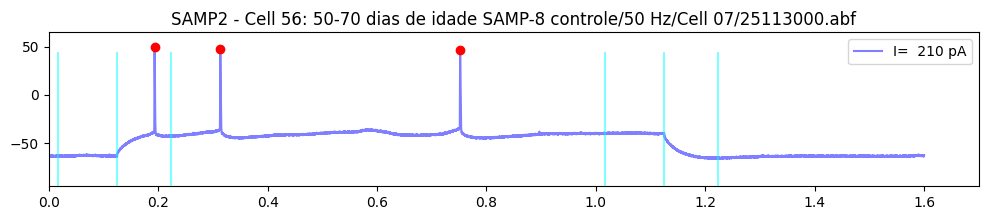

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 08 /25221009.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


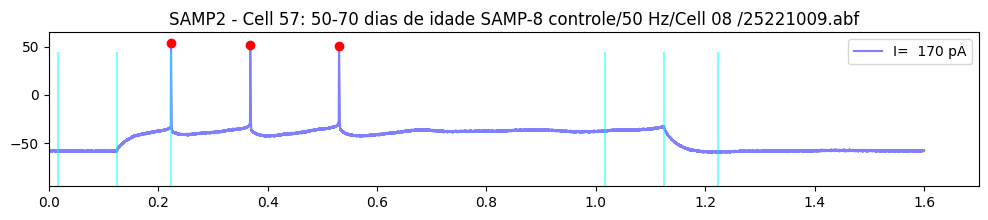

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 09/25311000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 01 - 500nM/24311000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


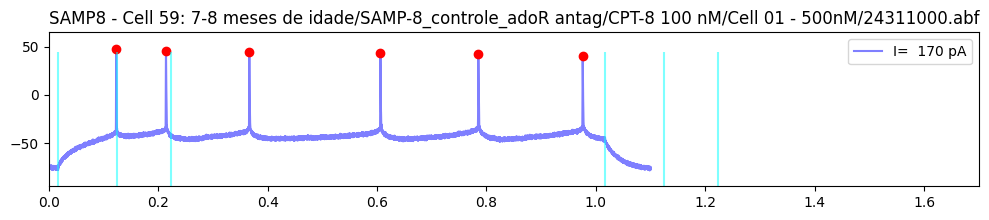

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 02 - 500 nM/24311012.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


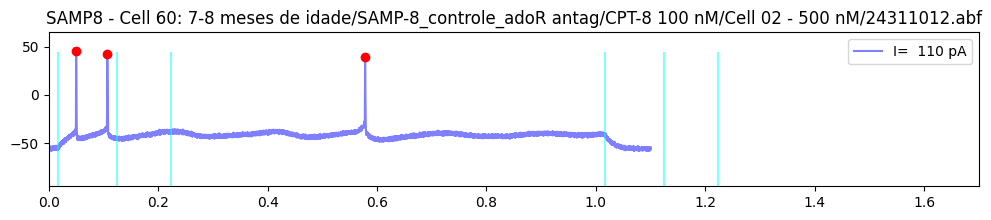

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 03 - 500nM/24311027.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 04 - 100nM/24315037.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


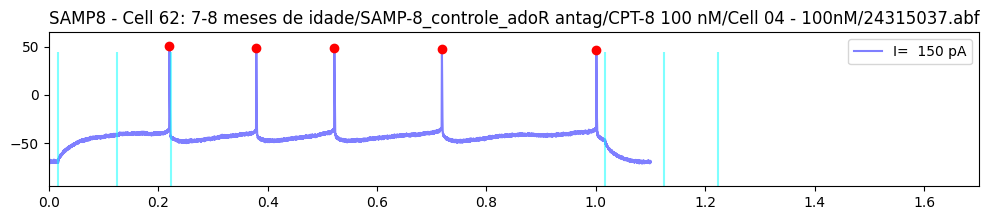

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 05 - 100 nM/24315048.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


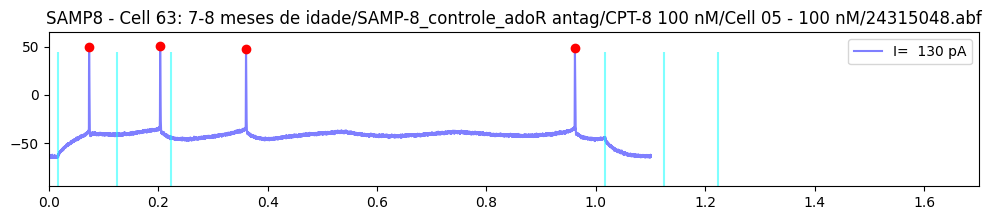

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 06 - 100nM/24318000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


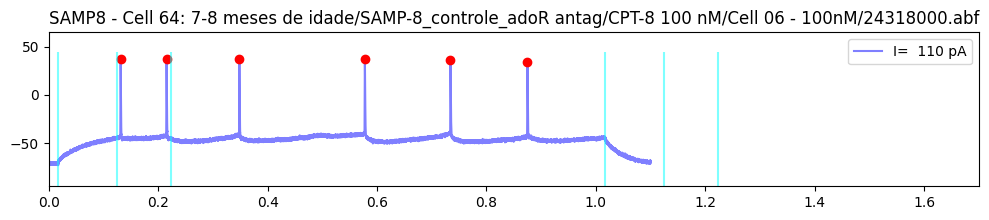

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 07 - 100nM/24318007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 08 - 100nM/24318013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


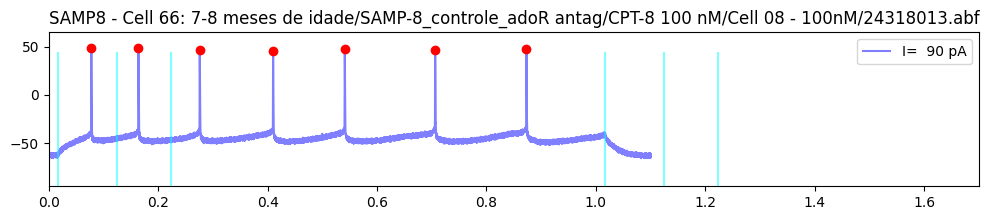

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 09 - 100nM/24318027.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 10 - 100nM/24319014.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


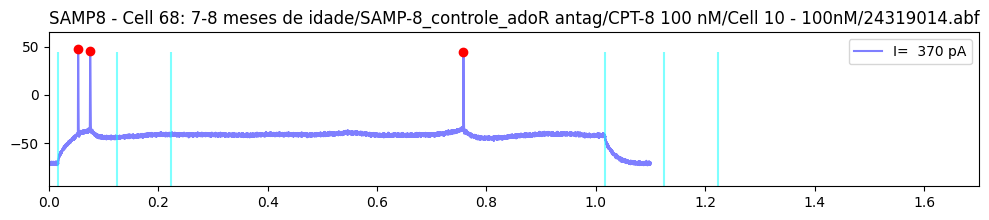

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 11 - 100nM/24319035.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 12 - 100&500nM/24320007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


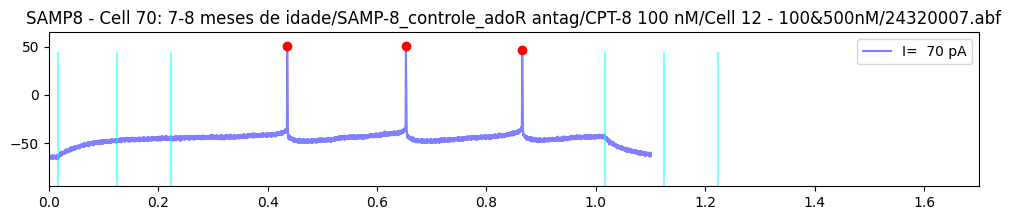

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 13 - 500nM/24320025.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


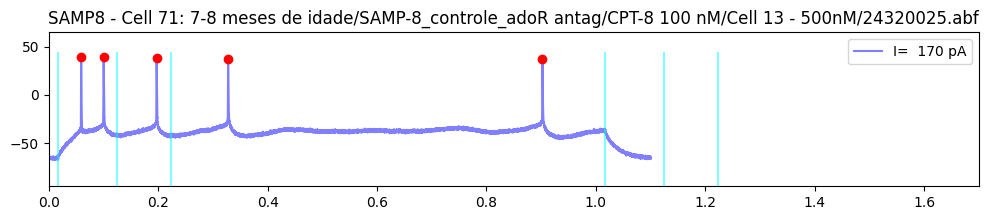

7-8 meses de idade/Agon. A2Ar 60nM/Cell 01/24618007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/Agon. A2Ar 60nM/Cell 02/25403000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


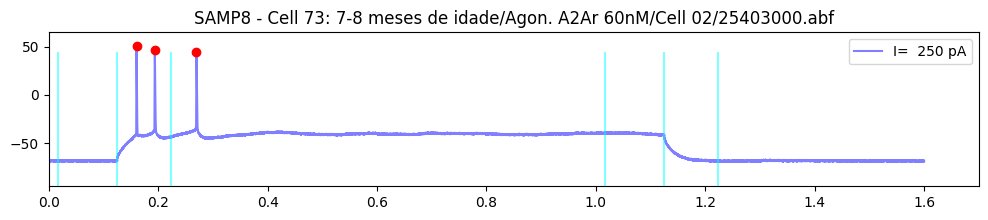

7-8 meses de idade/Agon. A2Ar 60nM/Cell 03/25403038.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


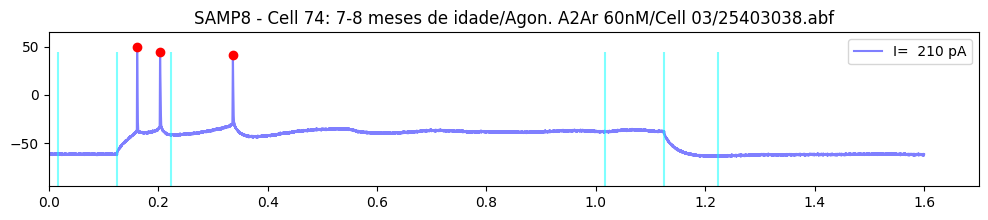

7-8 meses de idade/Agon. A2Ar 60nM/Cell 04/25404007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


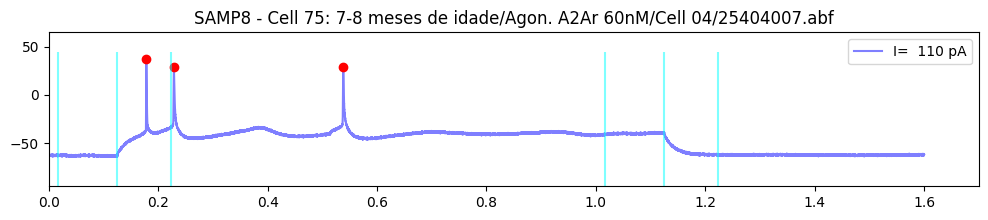

7-8 meses de idade/Agon. A2Ar 60nM/Cell 05/25410006.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


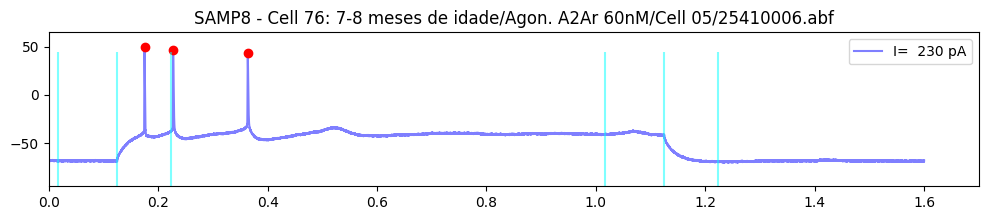

7-8 meses de idade/Agon. A2Ar 60nM/Cell 06/25411018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


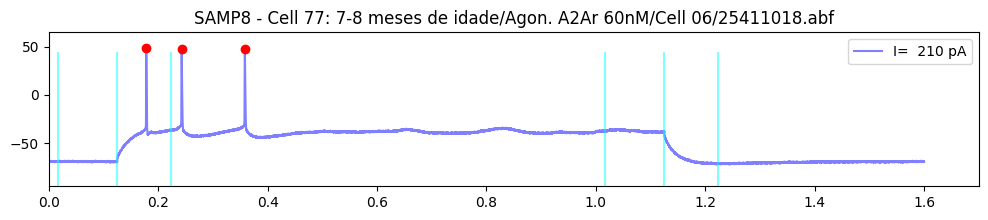

7-8 meses de idade/Agon. A2Ar 60nM/Cell 07 /25411010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


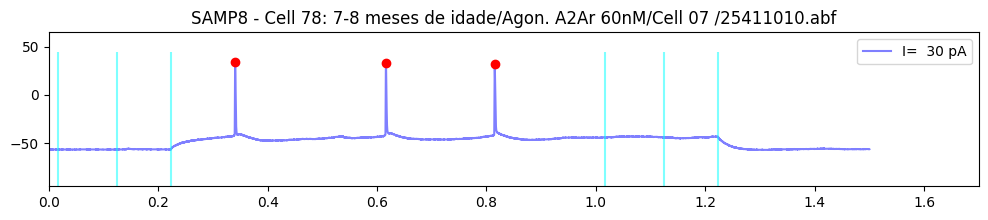

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 02/23424035.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


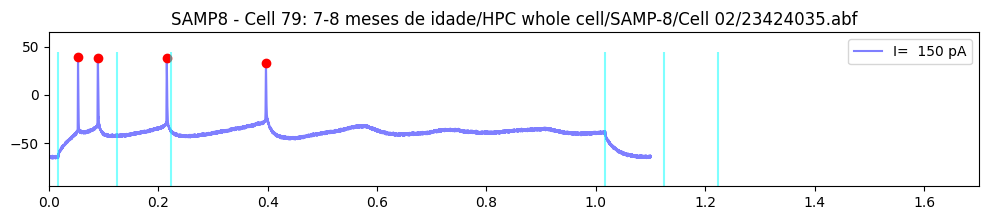

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 04/23425000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


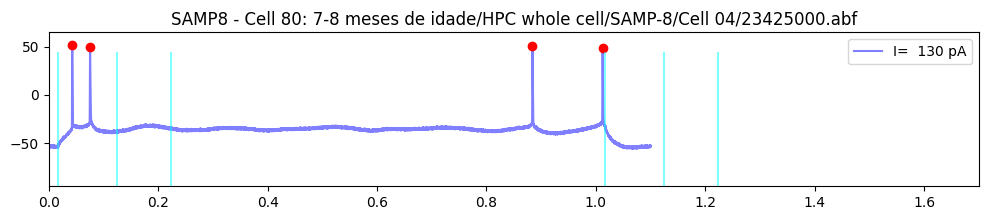

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 05/23425009.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


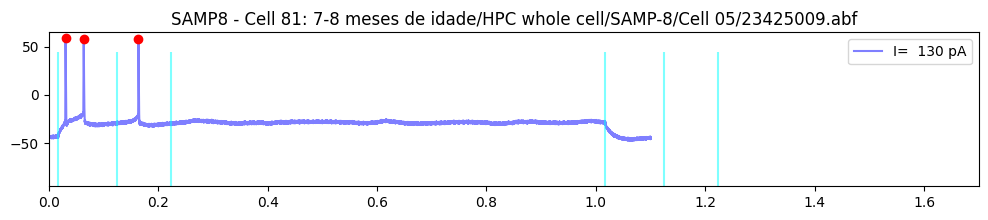

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 07/23d15000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


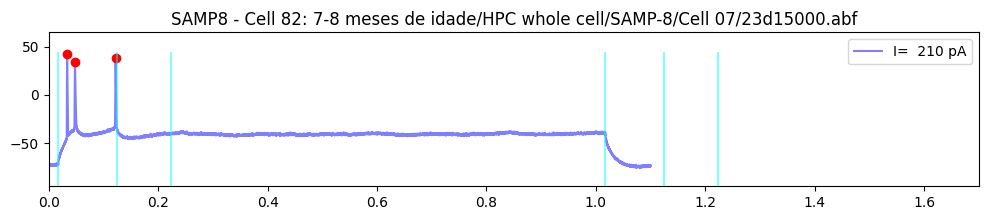

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 08/23d15014.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


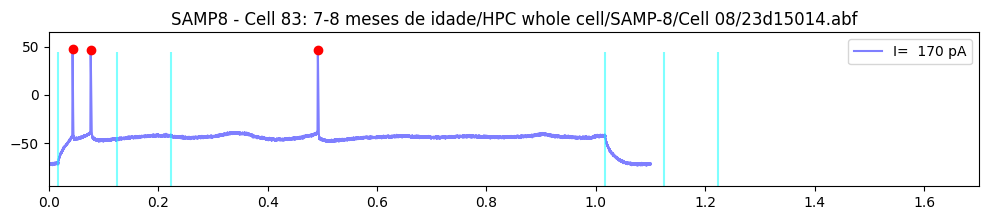

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 09/23d15025.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


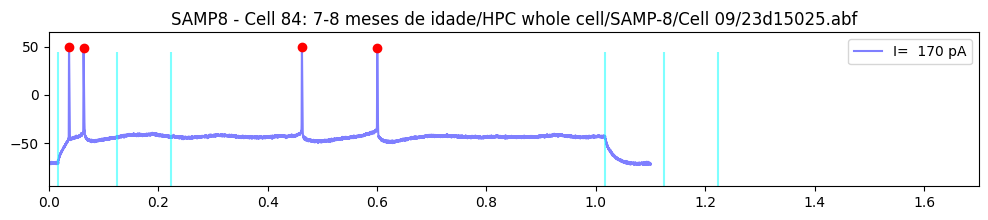

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 10/23d15040.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


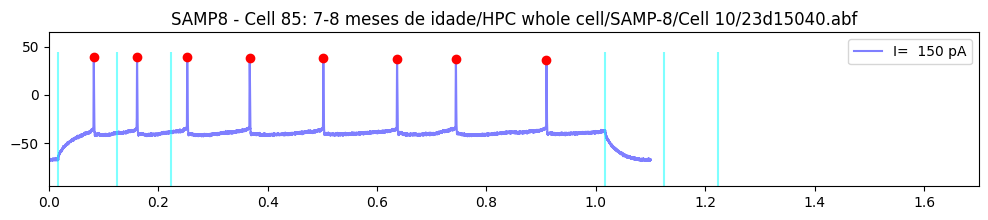

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 12/23d15075.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


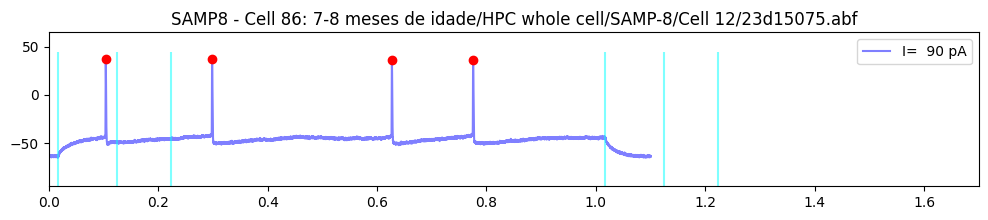

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 13/23d16010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


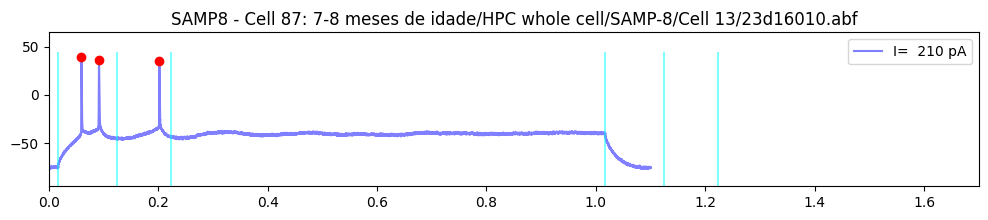

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 14/23d16013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


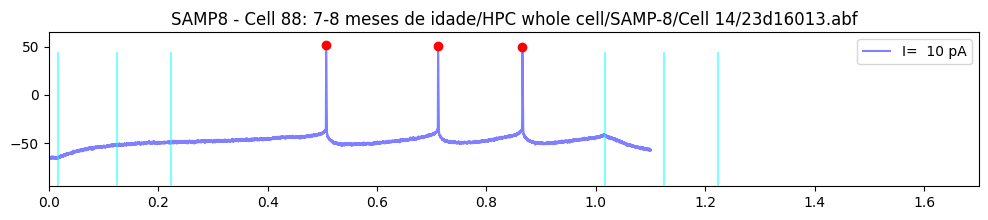

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 15/23d16021.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


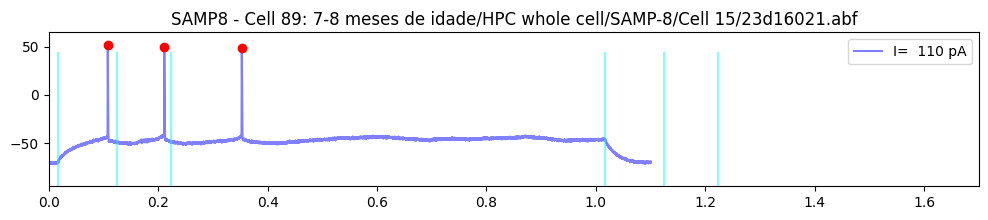

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 16/23d16029.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


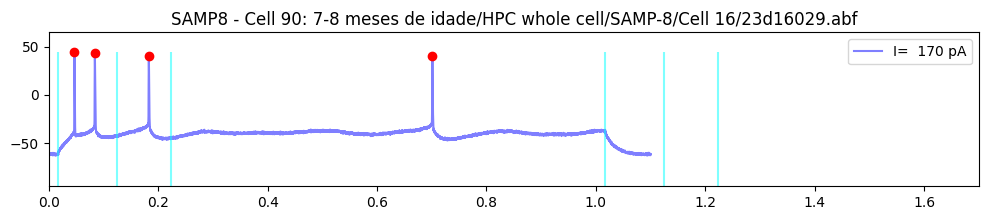

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 17/23d16038.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


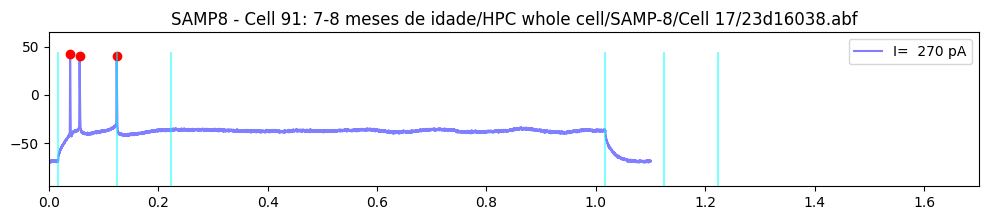

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 18/23d16053.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


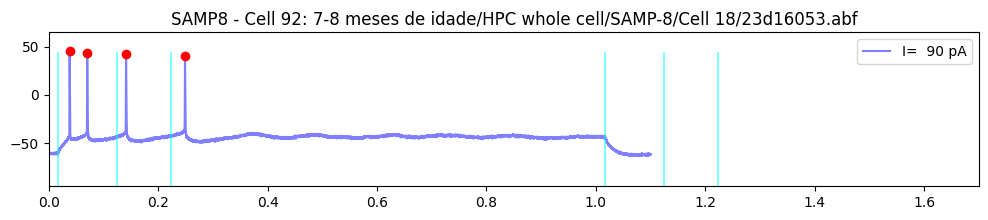

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 19/23d19000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


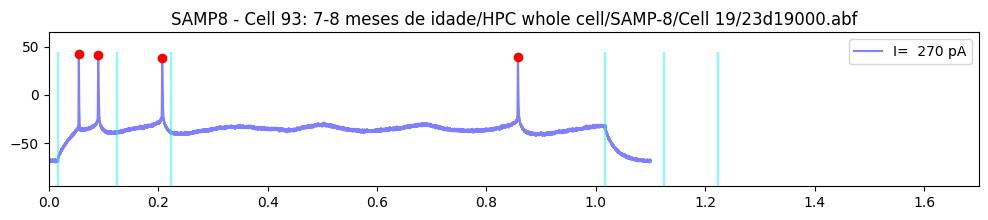

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 20/23d19016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


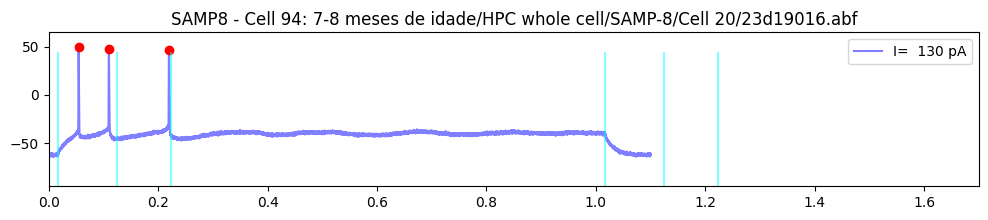

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 21/23d19035.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


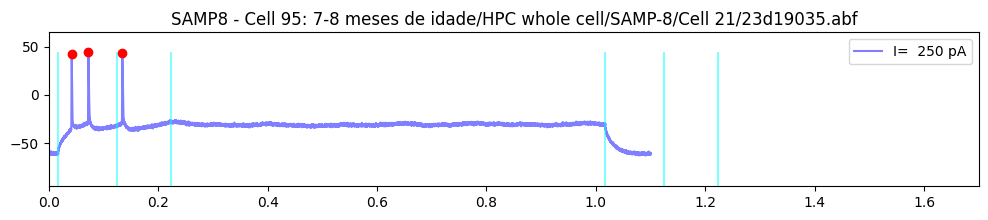

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 22/23d19050.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


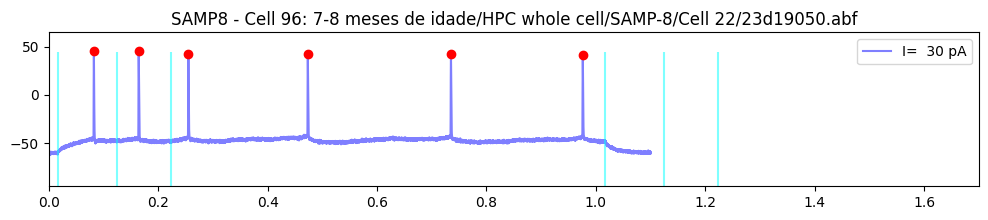

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 23/23d21000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 24/23d21007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 25/23d21012.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 26/23d21027.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 27/24311020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 28 - Incomplete/24517006.abf Long current step for 

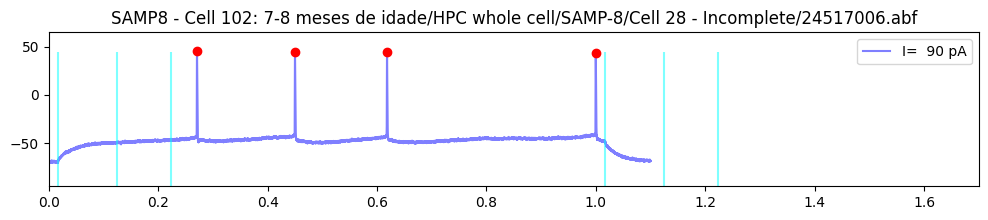

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 29 - Incomplete/24517011.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


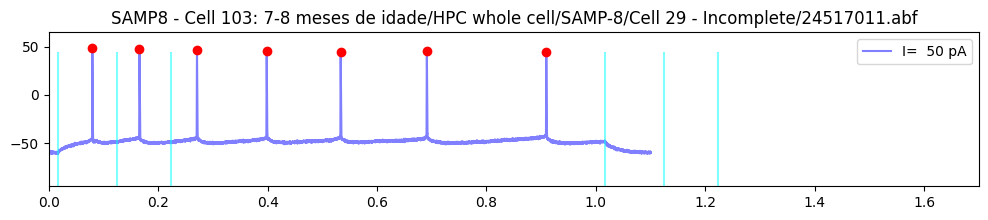

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 30 - Incomplete/24517014.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 31/24520008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


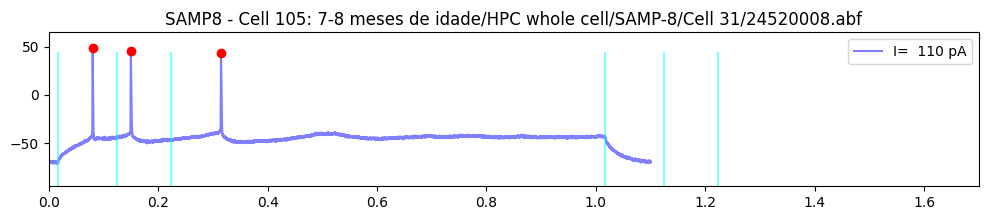

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 32/24520013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


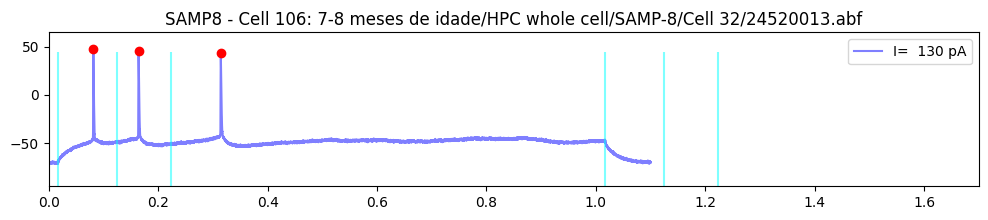

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 33/24520018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


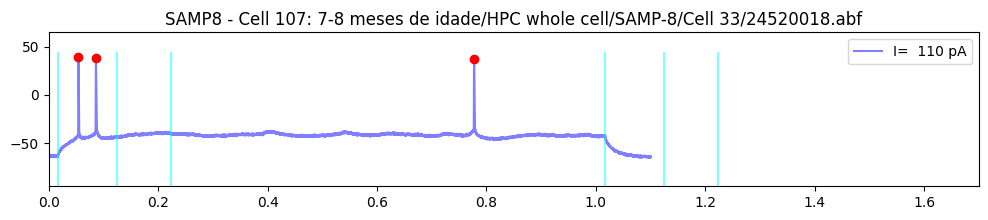

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 34/24521008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


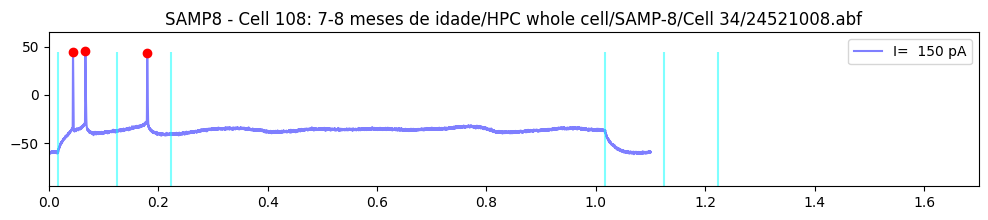

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 35/24521014.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


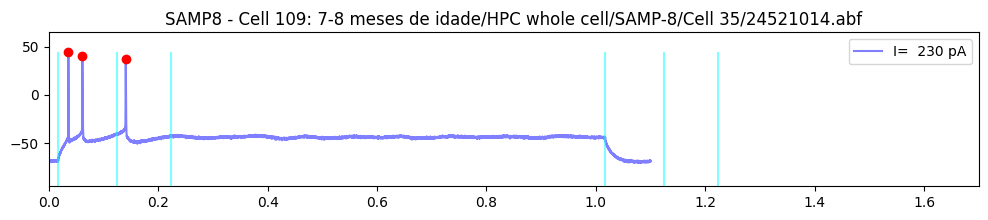

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 36/24618000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 37/24618002.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/10 Hz - 50 pulses/Cell 01/25313045.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


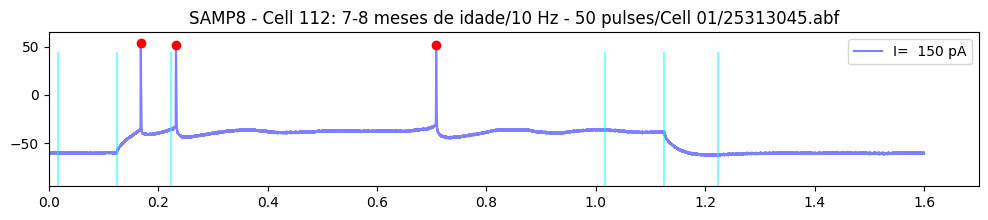

7-8 meses de idade/10 Hz - 50 pulses/Cell 02/25324034.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


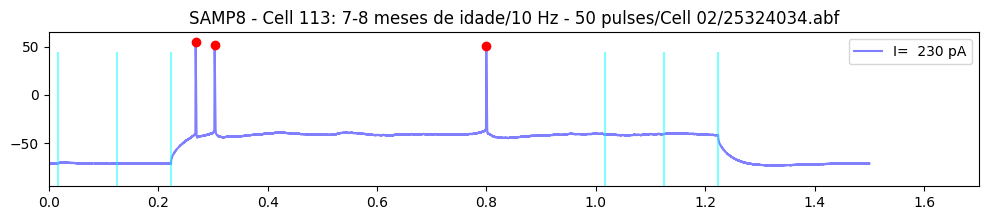

7-8 meses de idade/10 Hz - 50 pulses/Cell 03/25324049.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


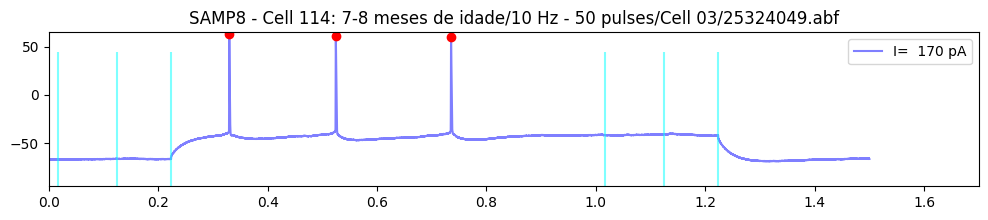

7-8 meses de idade/10 Hz - 50 pulses/Cell 04/25325000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


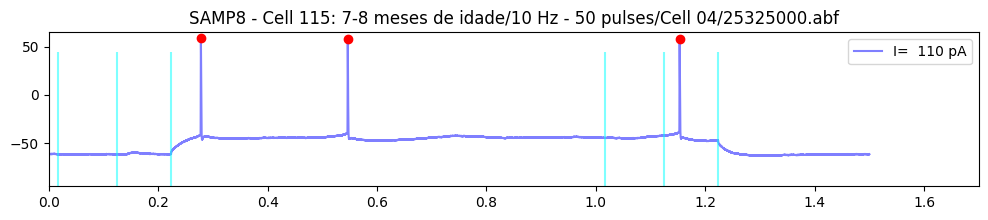

7-8 meses de idade/10 Hz - 50 pulses/Cell 05/25328006.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


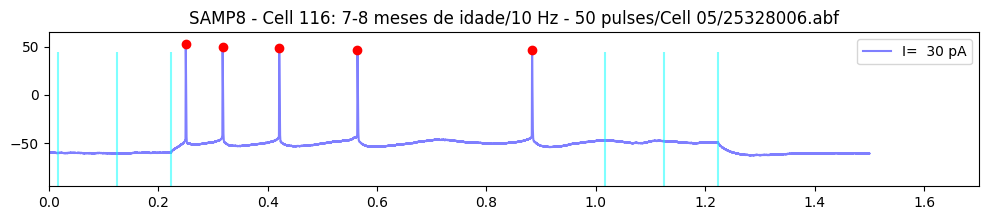

7-8 meses de idade/10 Hz - 50 pulses/Cell 06/25328023.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


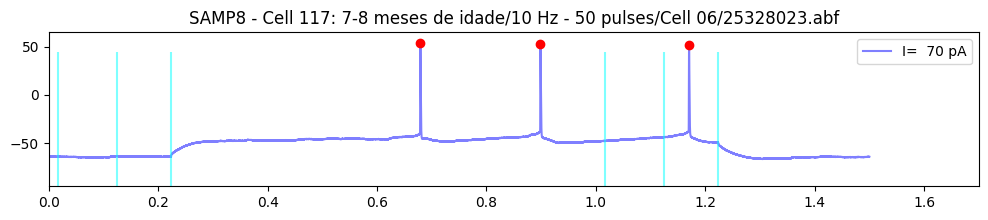

7-8 meses de idade/10 Hz - 50 pulses/Cell 07/25403021.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


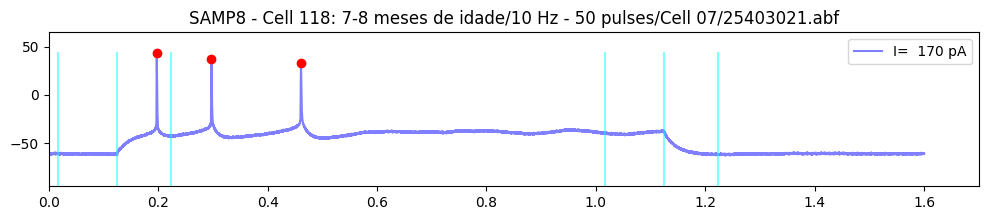

7-8 meses de idade/10 Hz - 50 pulses/Cell 08 /25403000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


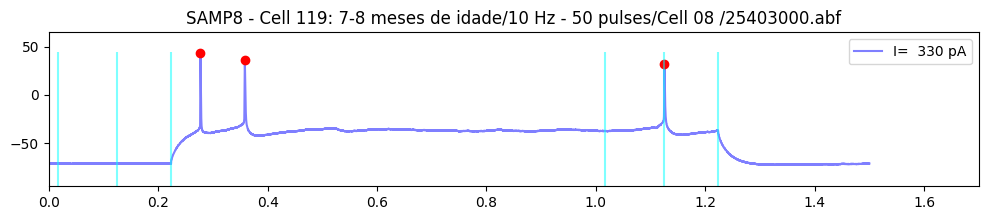

7-8 meses de idade/100 Hz - 50 pulses/Cell 01 /25324012.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


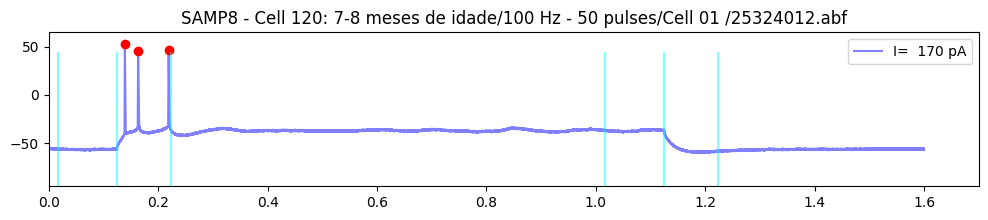

7-8 meses de idade/100 Hz - 50 pulses/Cell 02/25325010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/100 Hz - 50 pulses/Cell 03/25325020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


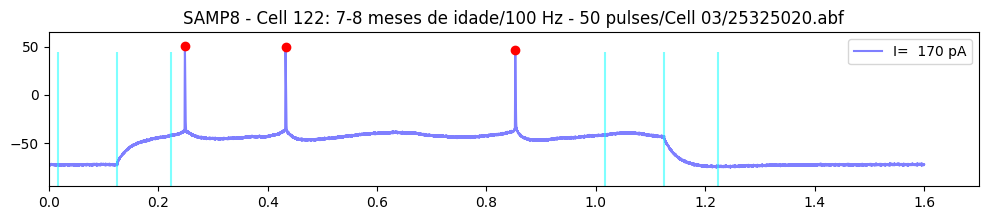

7-8 meses de idade/100 Hz - 50 pulses/Cell 04/25328000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


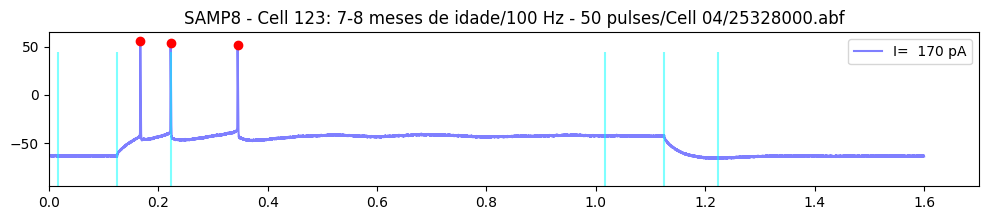

7-8 meses de idade/100 Hz - 50 pulses/Cell 05/25328010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


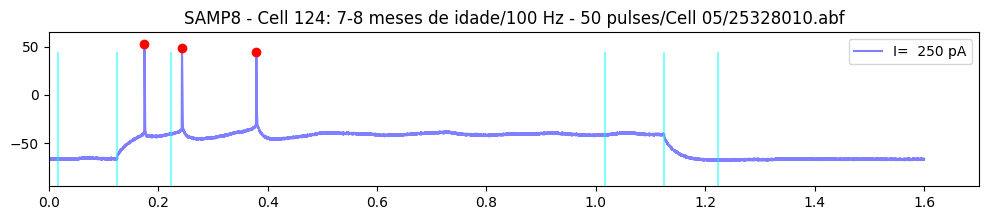

7-8 meses de idade/100 Hz - 50 pulses/Cell 06/25328018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


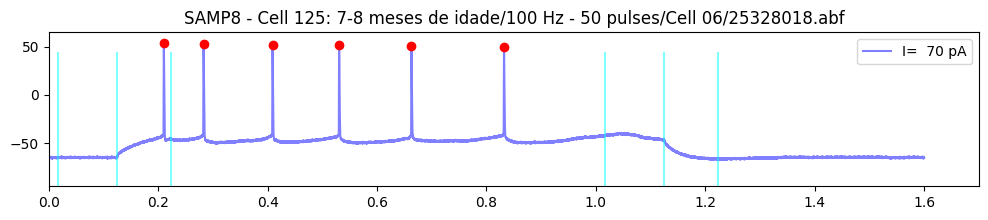

7-8 meses de idade/100 Hz - 50 pulses/Cell 07/25402004.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


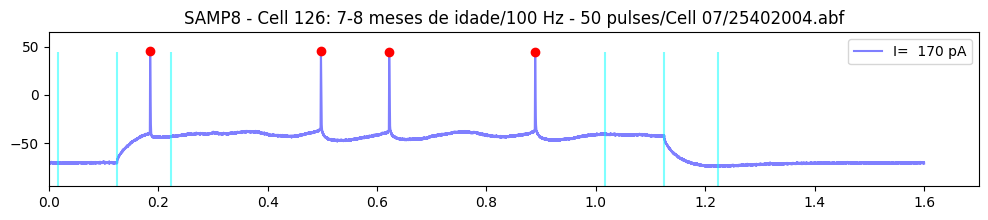

7-8 meses de idade/50 Hz/Controle/Cell 01/24322007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


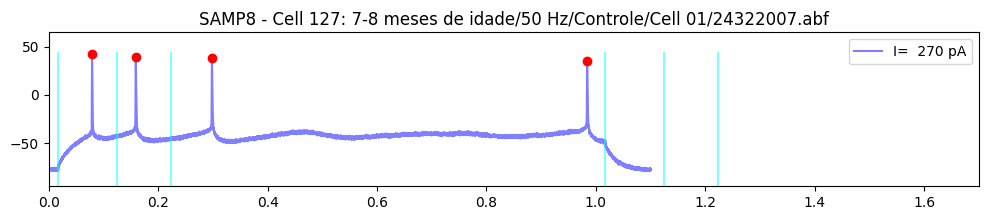

7-8 meses de idade/50 Hz/Controle/Cell 02/24322017.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


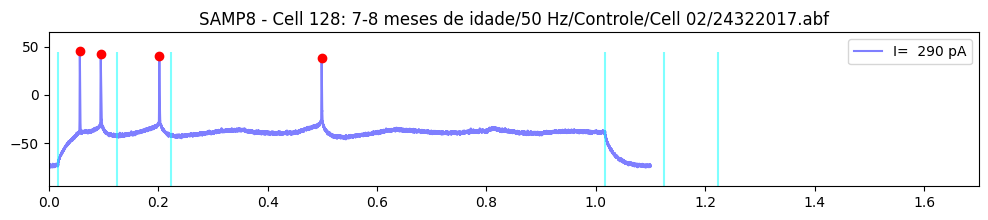

7-8 meses de idade/50 Hz/Controle/Cell 03/24325050.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


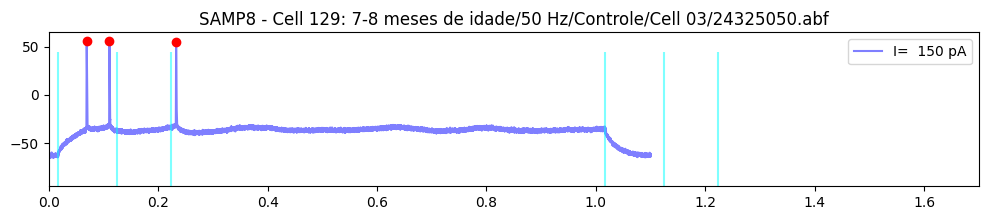

7-8 meses de idade/50 Hz/Controle/Cell 04/24325059.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


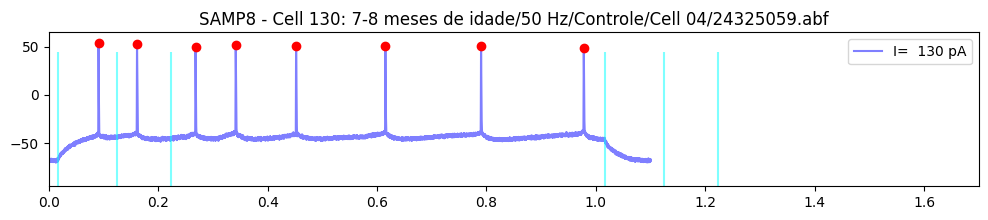

7-8 meses de idade/50 Hz/Controle/Cell 05/24516000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


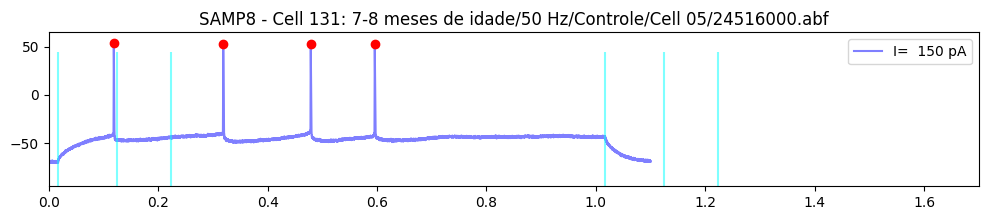

7-8 meses de idade/50 Hz/Controle/Cell 06/24516024.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


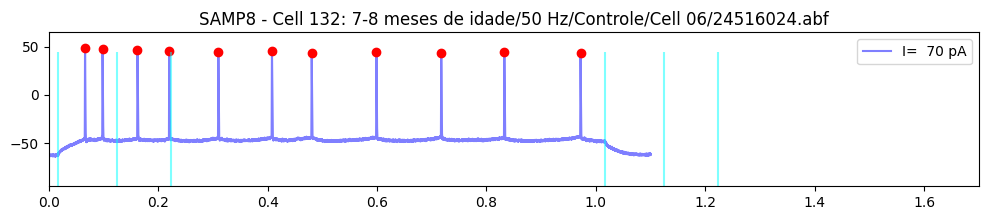

7-8 meses de idade/50 Hz/Controle/Cell 07/24404018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


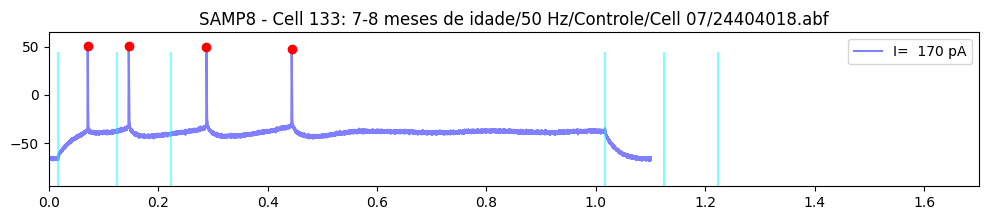

7-8 meses de idade/50 Hz/Controle/Cell 08 - Incomplete/24408020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


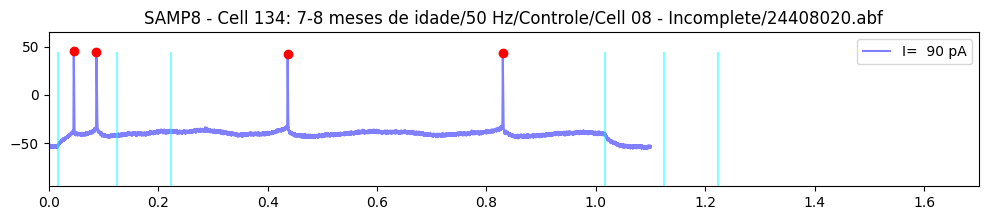

7-8 meses de idade/50 Hz/Controle/Cell 09 - Incomplete/24516008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


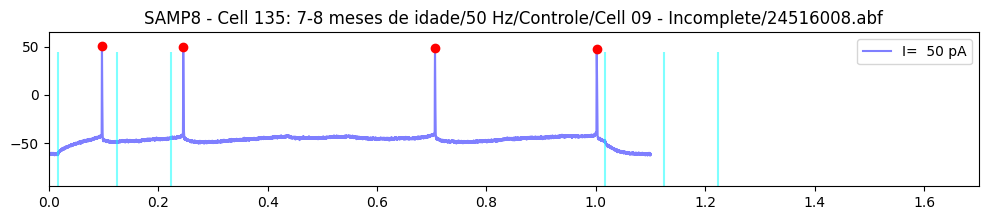

7-8 meses de idade/50 Hz/Controle/Cell 11 - Incomplete/24516019.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


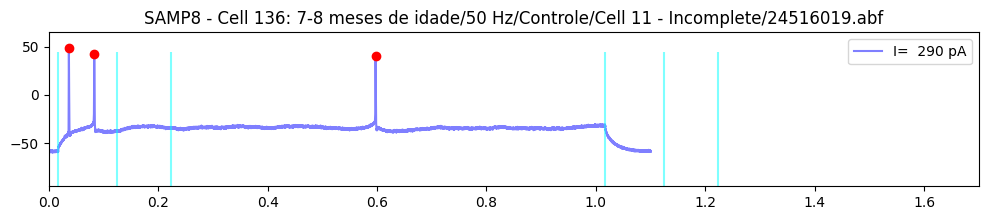

7-8 meses de idade/50 Hz/Controle/Cell 12 - incomplete/24520000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


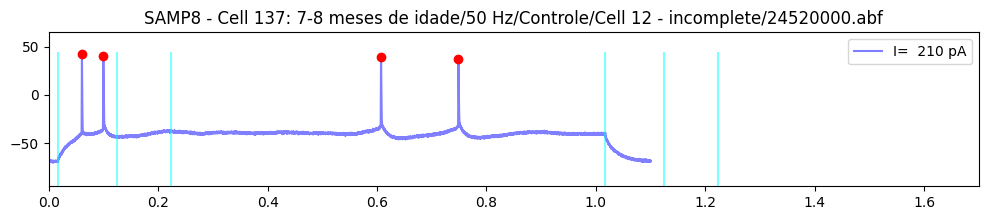

7-8 meses de idade/50 Hz/Controle/Cell 14/25313000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


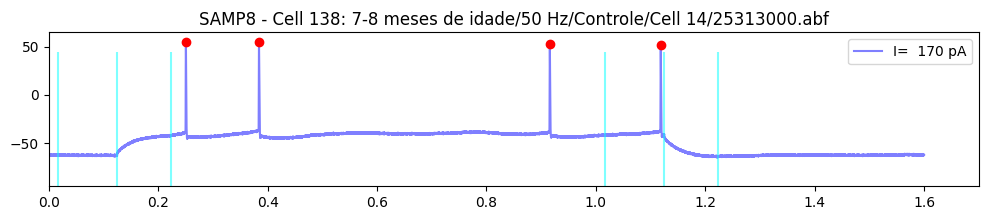

7-8 meses de idade/Cafeina/ZM - Antag. A2AR/Cell 01/24403022.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]


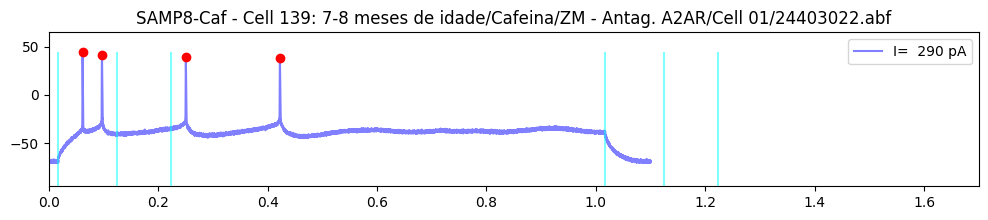

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 01/24525030.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


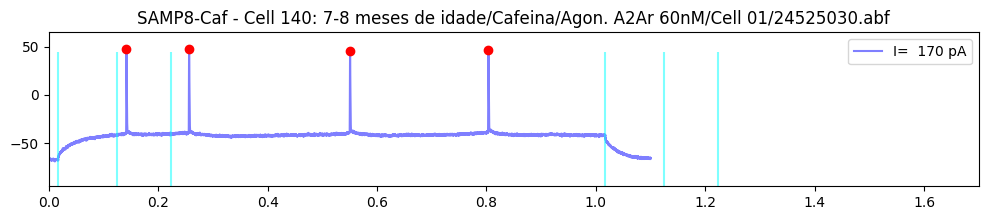

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 02/24606000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


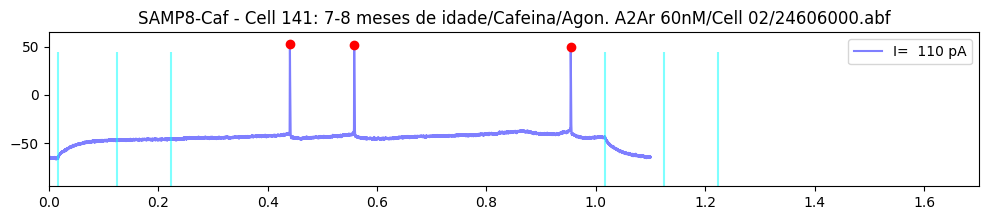

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 03/24607002.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


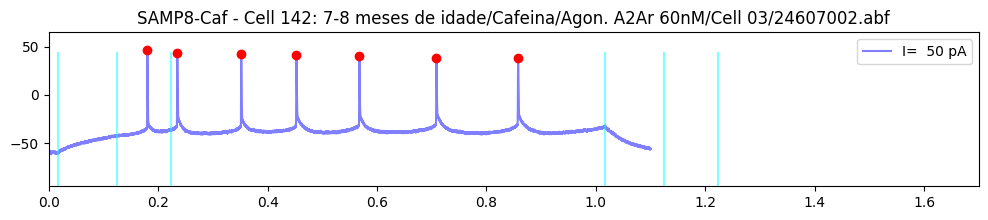

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 04/24607010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


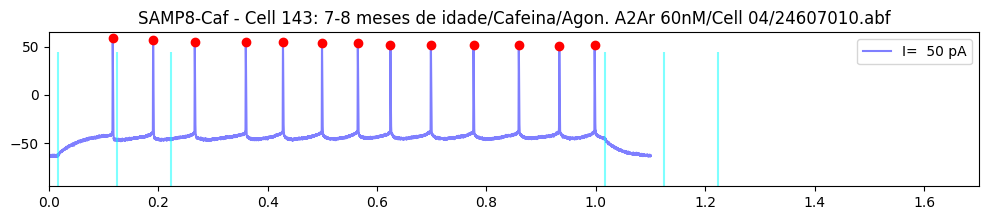

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 05/24608009.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


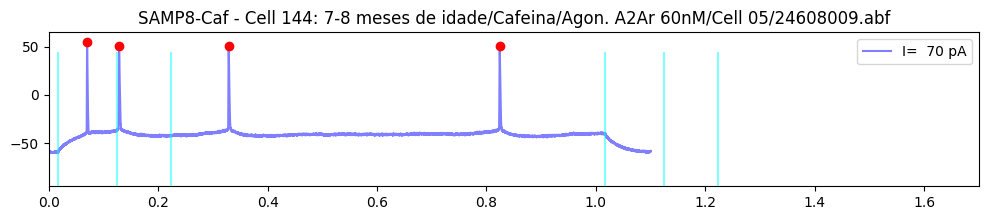

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 06/24o15020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


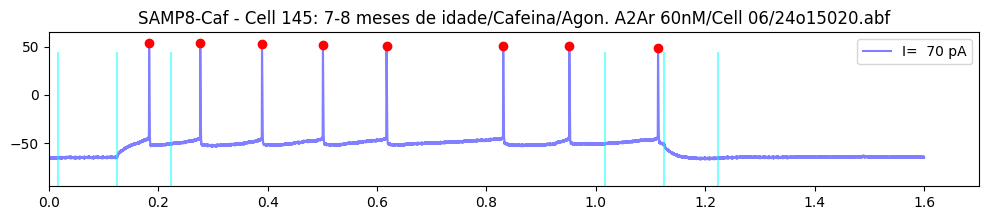

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 08/25207021.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


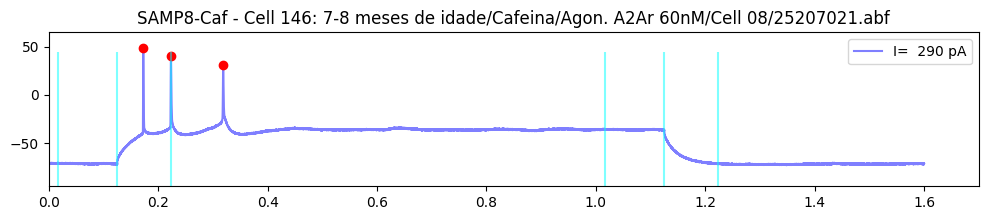

7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 01/24327029.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


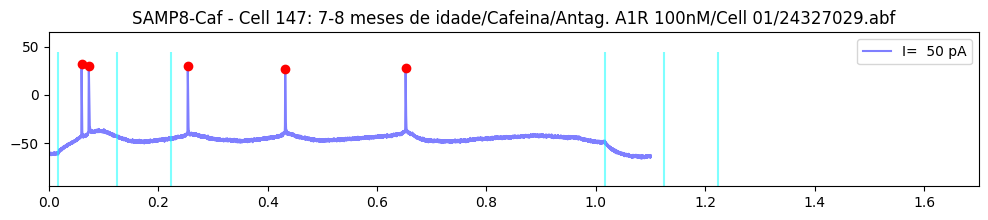

7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 03/24328025.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 04/24329000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


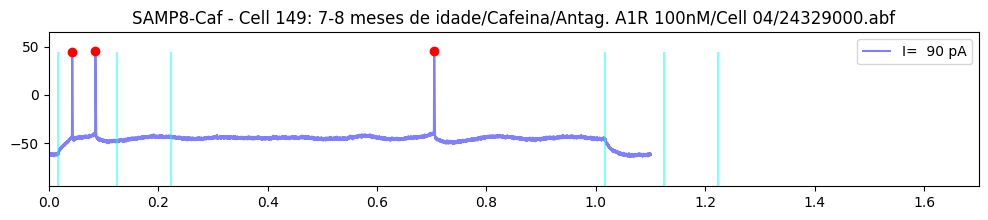

7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 05/24329019.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 06/24329027.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


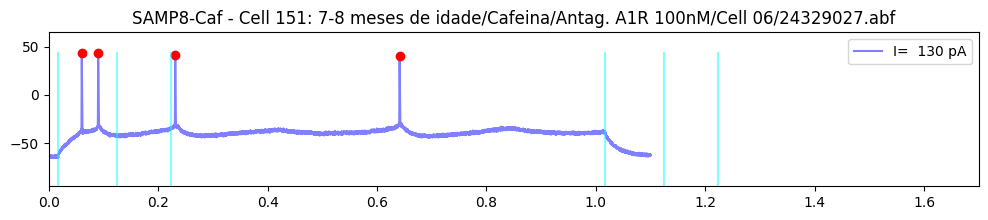

7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 07/24401010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 08/24401018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/Cafeina/Patch HPC/Cell 07/24210000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


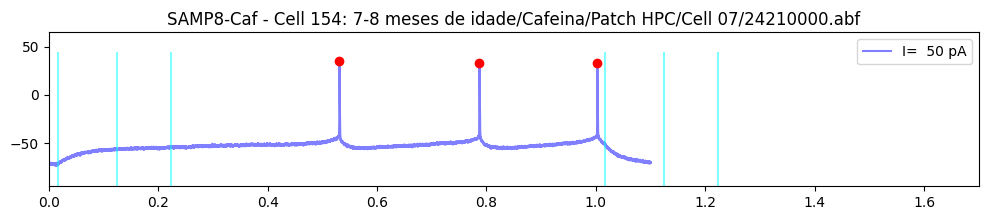

7-8 meses de idade/Cafeina/Patch HPC/Cell 08/24210020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


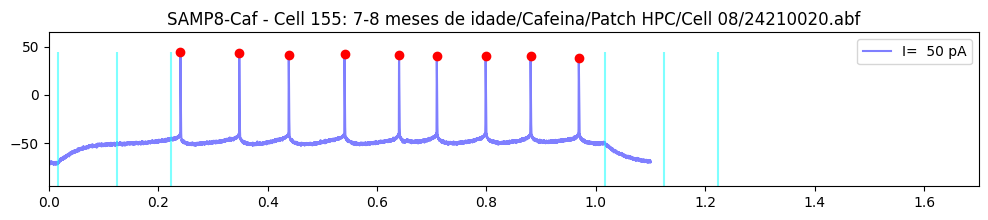

7-8 meses de idade/Cafeina/Patch HPC/Cell 09/24210053.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


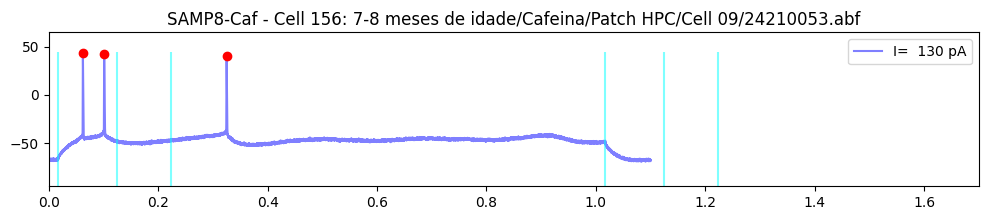

7-8 meses de idade/Cafeina/Patch HPC/Cell 10/24210069.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


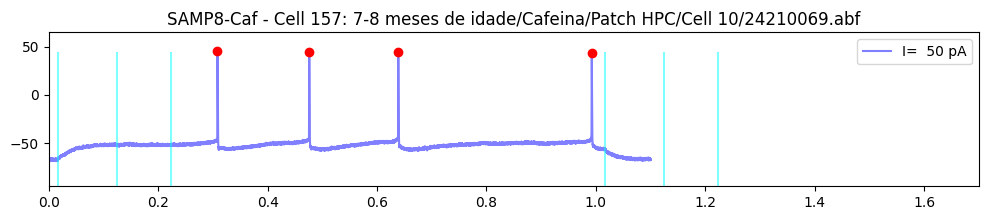

7-8 meses de idade/Cafeina/Patch HPC/Cell 11/24212039.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


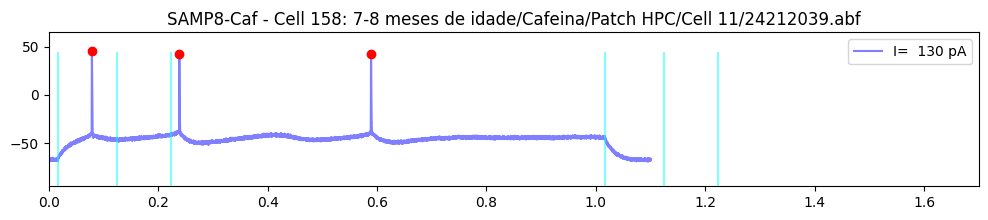

7-8 meses de idade/Cafeina/Patch HPC/Cell 12/24212055.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


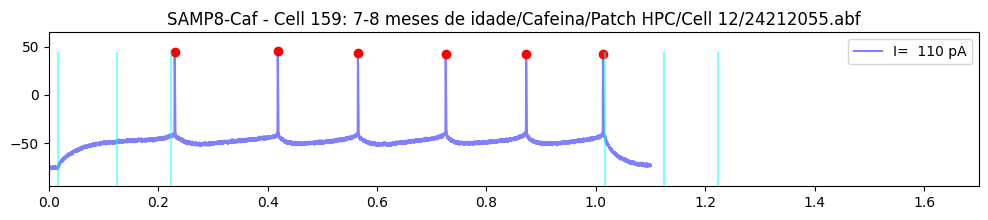

7-8 meses de idade/Cafeina/Patch HPC/Cell 13/24212071.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


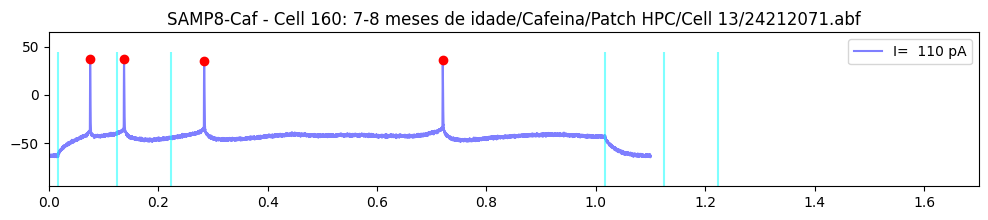

7-8 meses de idade/Cafeina/Patch HPC/Cell 14/24214059.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


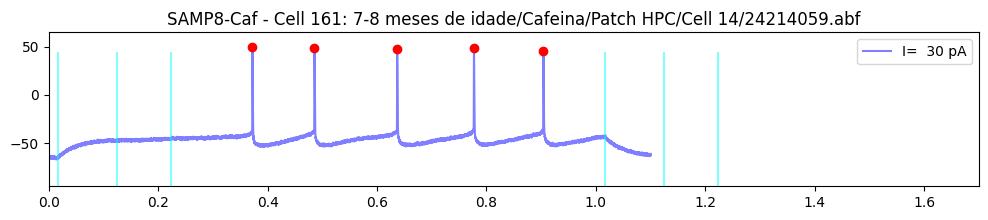

7-8 meses de idade/Cafeina/Patch HPC/Cell 15/24214079.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


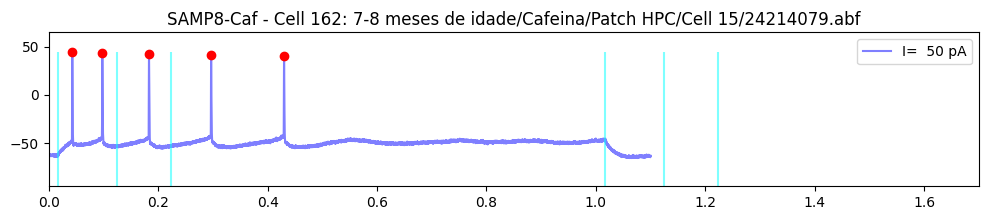

7-8 meses de idade/Cafeina/Patch HPC/Cell 16/24216001.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/Cafeina/Patch HPC/Cell 17/24216017.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


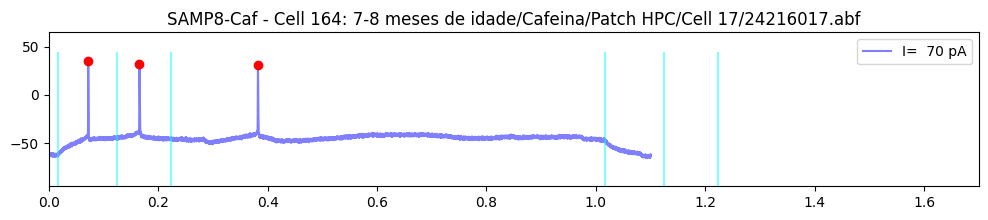

7-8 meses de idade/Cafeina/Patch HPC/Cell 18/24216020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


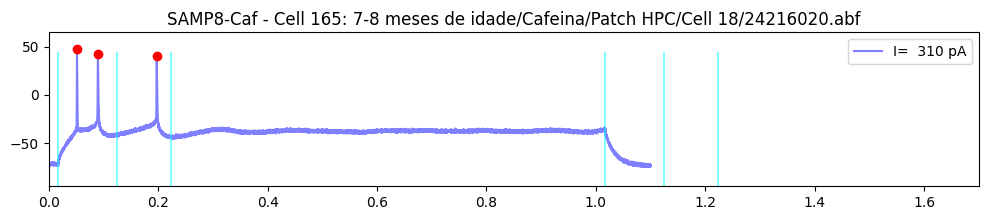

7-8 meses de idade/Cafeina/Patch HPC/Cell 19/24216072.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


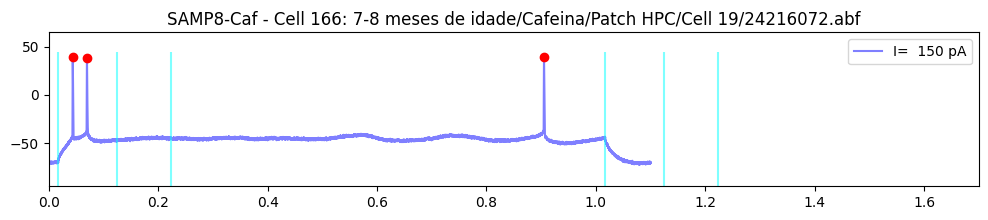

7-8 meses de idade/Cafeina/Patch HPC/Cell 20/24217072.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


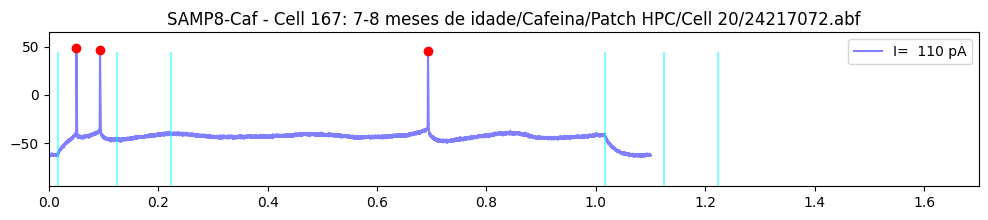

7-8 meses de idade/Cafeina/Patch HPC/Cell 21/24217084.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


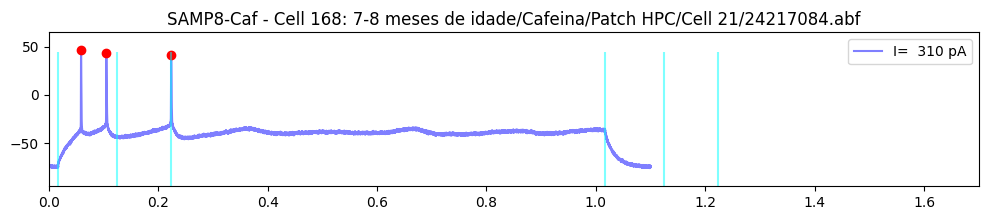

7-8 meses de idade/Cafeina/Patch HPC/Cell 22/24219000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


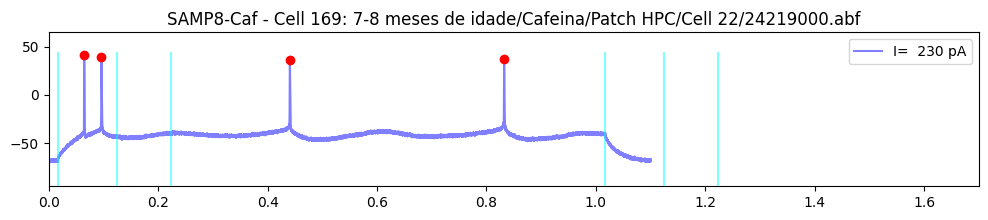

7-8 meses de idade/Cafeina/Patch HPC/Cell 23/24219016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


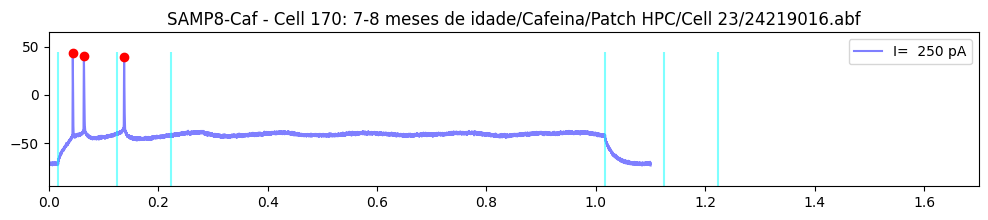

7-8 meses de idade/Cafeina/Patch HPC/Cell 24/24220000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


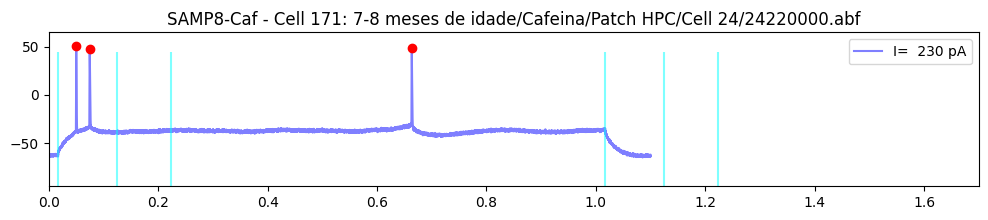

7-8 meses de idade/Cafeina/Patch HPC/Cell 25/24220016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
7-8 meses de idade/Cafeina/Patch HPC/Cell 26/24220032.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


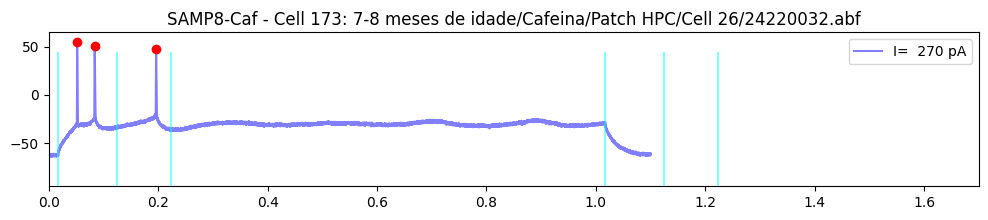

7-8 meses de idade/Cafeina/Patch HPC/Cell 27/24220099.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


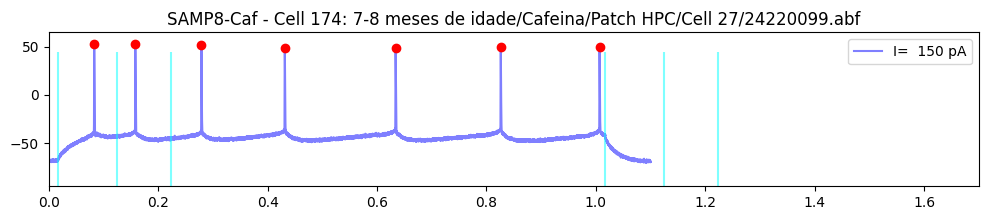

7-8 meses de idade/Cafeina/Patch HPC/Cell 28/24220115.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


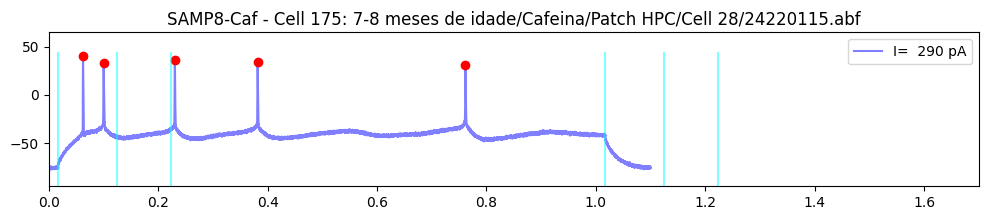

7-8 meses de idade/Cafeina/Patch HPC/Cell 29/24327008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


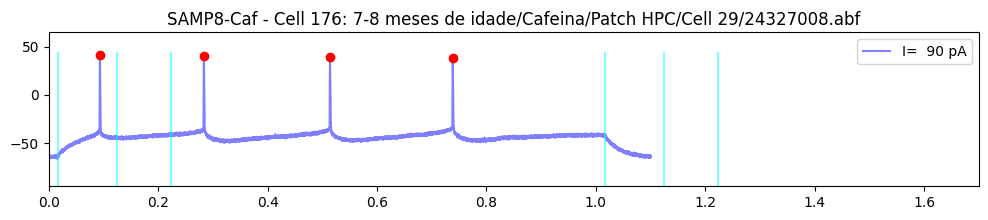

7-8 meses de idade/Cafeina/Patch HPC/Cell 30/24327018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


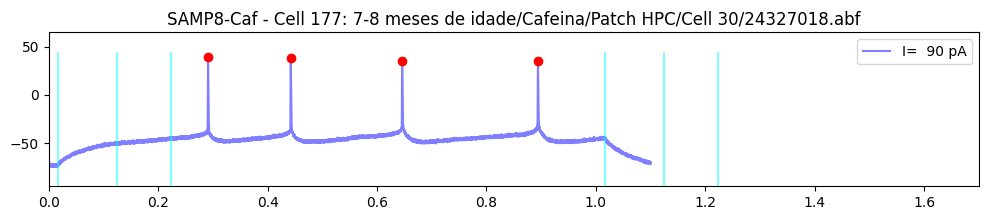

7-8 meses de idade/Cafeina/Patch HPC/Cell 32/24327036.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


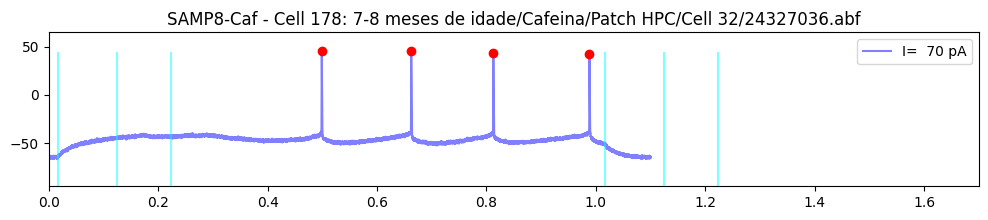

7-8 meses de idade/Cafeina/Patch HPC/Cell 33/24410008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
7-8 meses de idade/Cafeina/Patch HPC/Cell 34/24410012.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
7-8 meses de idade/Cafeina/Patch HPC/Cell 35/24525010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


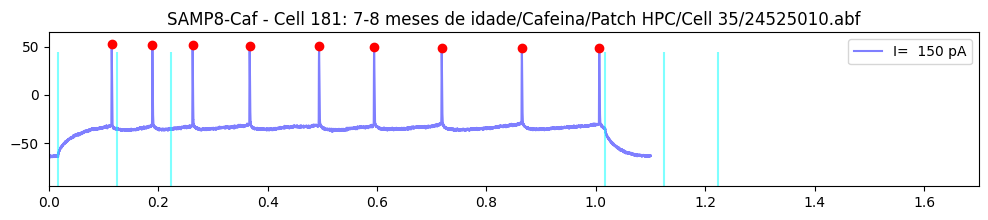

7-8 meses de idade/Cafeina/Patch HPC/Cell 36/24530000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


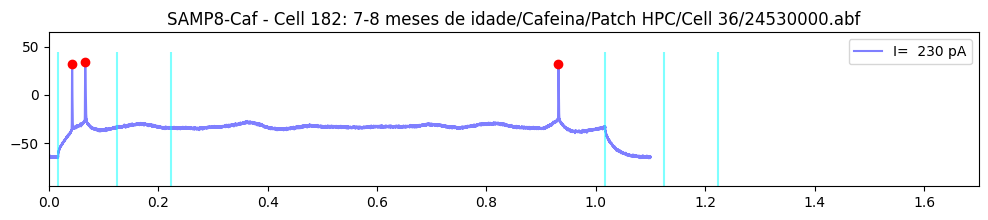

7-8 meses de idade/Cafeina/Patch HPC/Cell 37/24530002.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


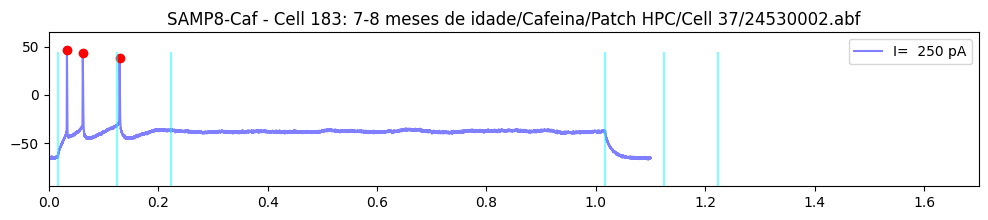

7-8 meses de idade/Cafeina/Patch HPC/Cell 38/24530008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


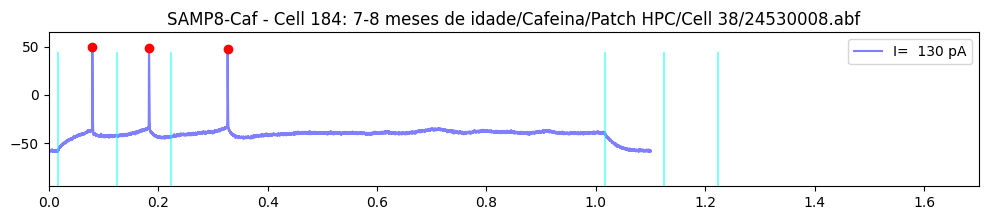

7-8 meses de idade/Cafeina/Patch HPC/Cell 39/24530013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


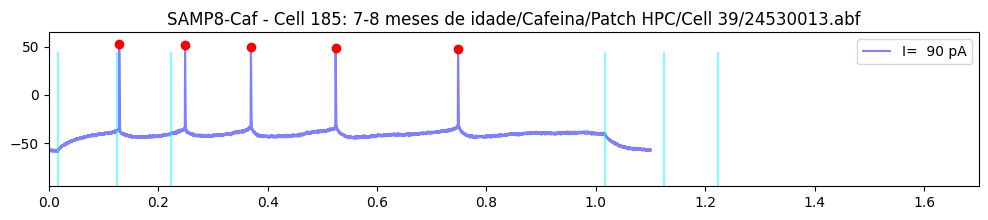

7-8 meses de idade/Cafeina/Patch HPC/Cell 40/24603000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


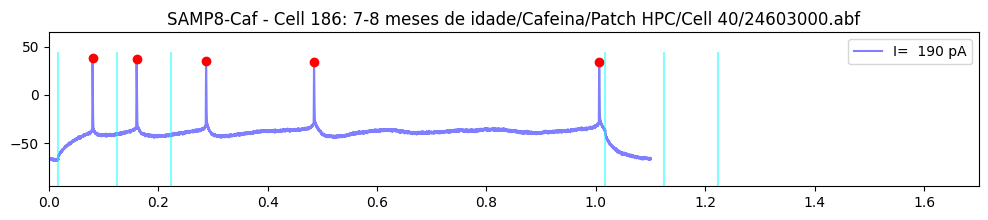

7-8 meses de idade/Cafeina/Patch HPC/Cell 41/24604000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


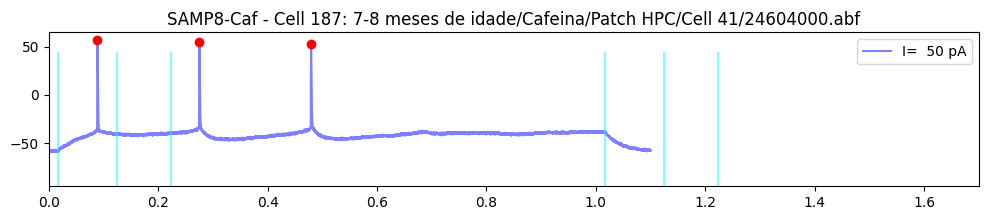

7-8 meses de idade/Cafeina/Patch HPC/Cell 42/24604013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


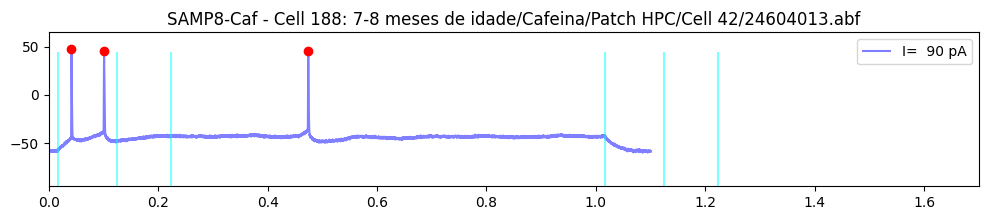

7-8 meses de idade/Cafeina/Patch HPC/Cell 43/24604018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


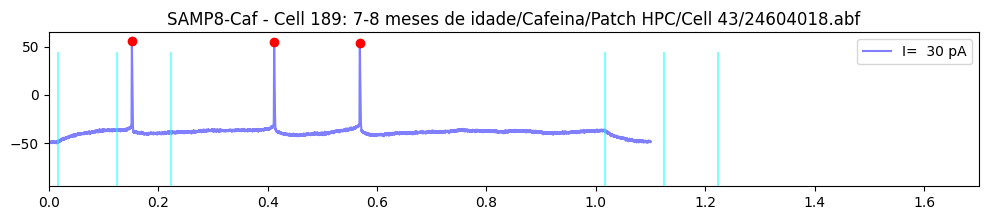

7-8 meses de idade/Cafeina/Patch HPC/Cell 44/24605000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/Cafeina/Patch HPC/Cell 46/24605010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


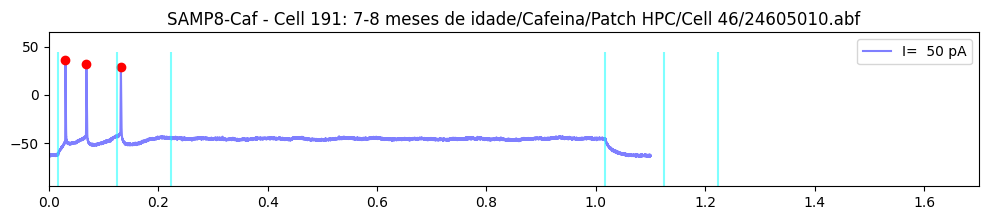

7-8 meses de idade/Cafeina/Patch HPC/Cell 47/24608000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


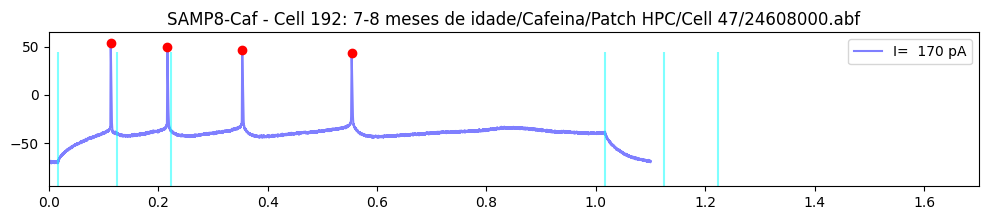

7-8 meses de idade/Cafeina/Patch HPC/Cell 48/24608003.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


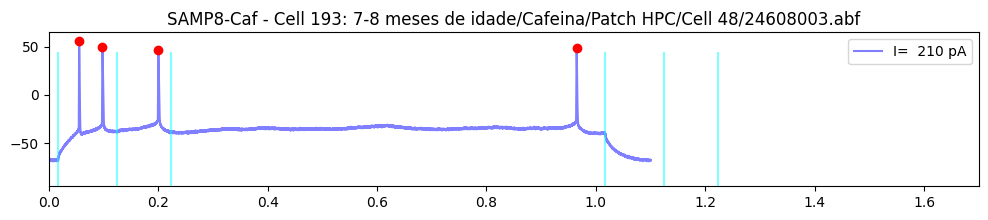

7-8 meses de idade/Cafeina/Patch HPC/Cell 49/25617018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


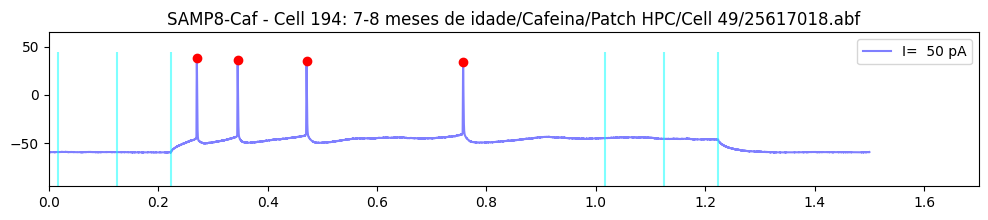

7-8 meses de idade/Cafeina/Patch HPC/Cell 50/25620003.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


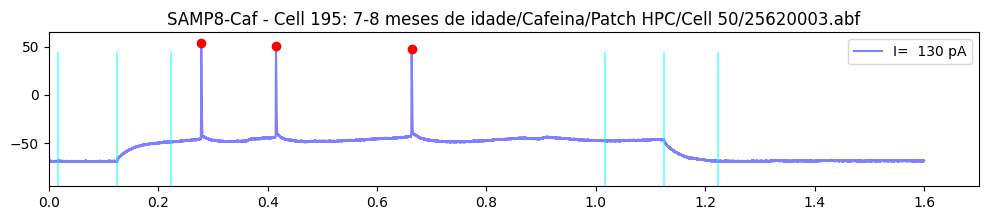

7-8 meses de idade/Cafeina/Patch HPC/Cell 51/25620019.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


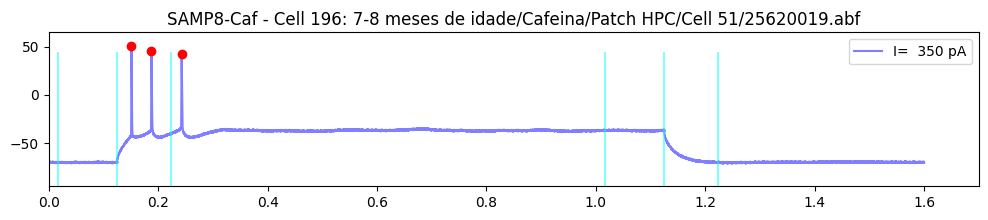

7-8 meses de idade/Cafeina/Patch HPC/Cell 52/25620035.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


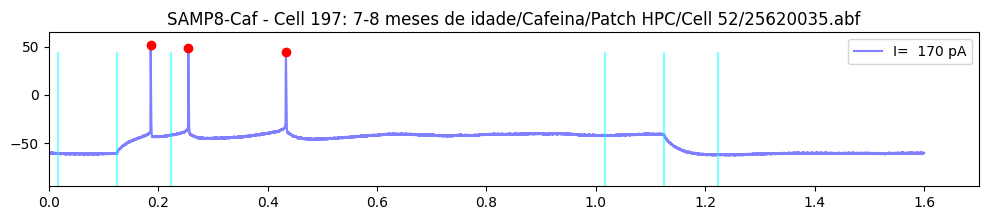

7-8 meses de idade/Cafeina/Patch HPC/Cell 53/25620051.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


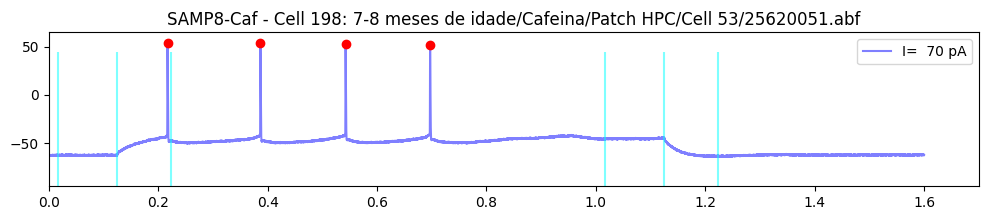

7-8 meses de idade/Cafeina/Patch HPC/Cell 54/25620000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
7-8 meses de idade/Cafeina/Patch HPC/Cell 55/25620016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


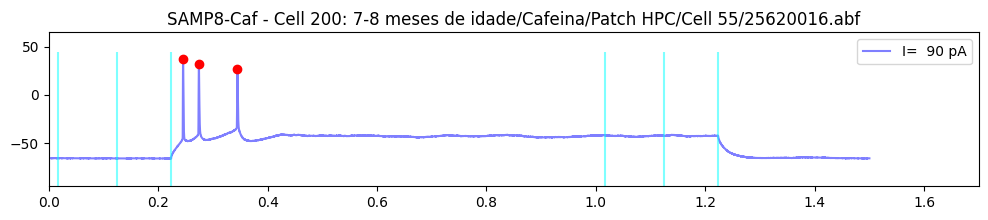

7-8 meses de idade/Cafeina/Patch HPC/Cell 56/26309000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
7-8 meses de idade/Cafeina/10 Hz/Cell 02/25130014.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


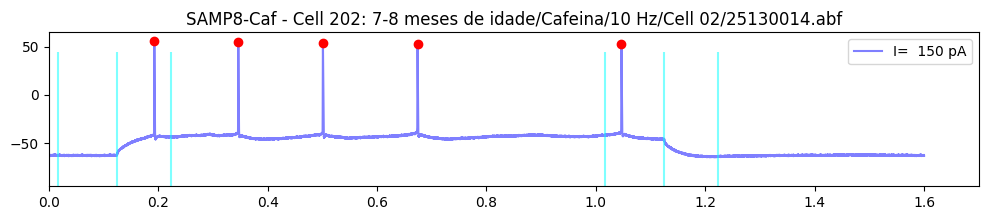

7-8 meses de idade/Cafeina/10 Hz/Cell 03/25131013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


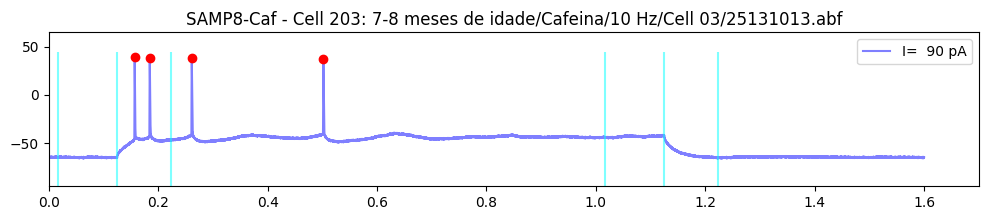

7-8 meses de idade/Cafeina/10 Hz/Cell 04/25203000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


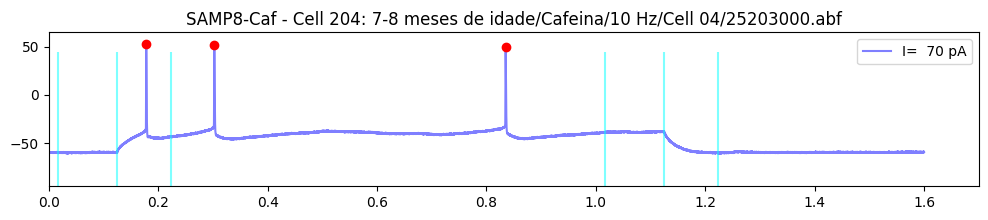

7-8 meses de idade/Cafeina/10 Hz/Cell 05/25206016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


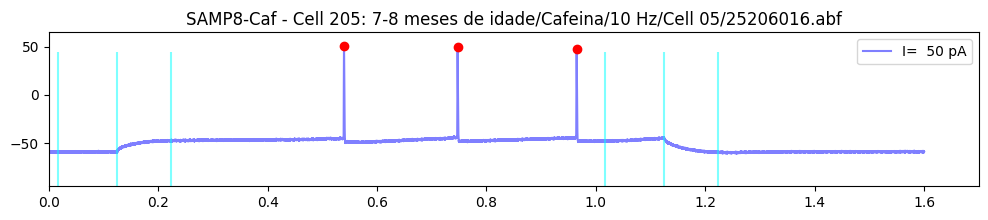

7-8 meses de idade/Cafeina/10 Hz/Cell 06/25207011.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


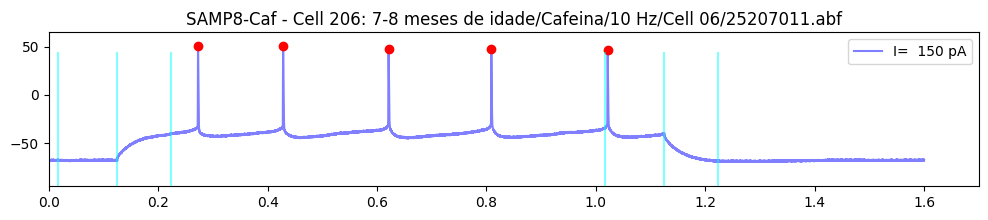

7-8 meses de idade/Cafeina/10 Hz/Cell 07 /25213022.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


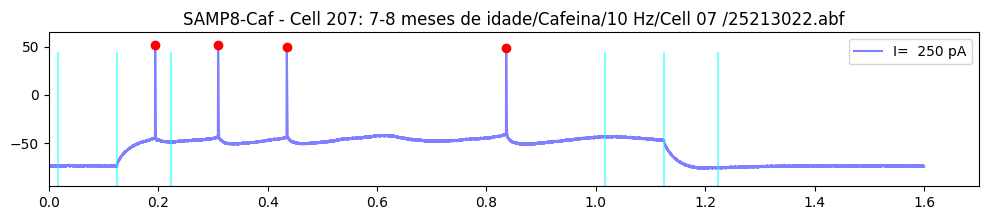

7-8 meses de idade/Cafeina/10 Hz/Cell 08 ** /25213012.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


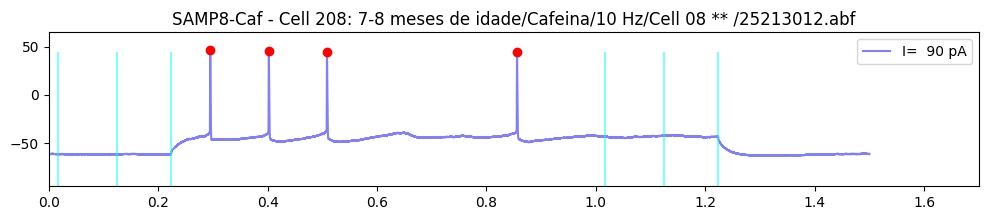

7-8 meses de idade/Cafeina/100 Hz/Cell 01/25130000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


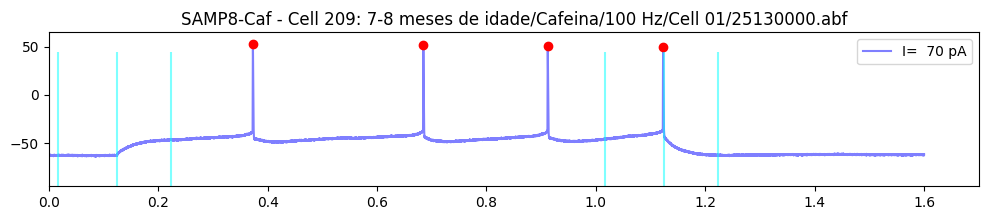

7-8 meses de idade/Cafeina/100 Hz/Cell 02/25131042.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


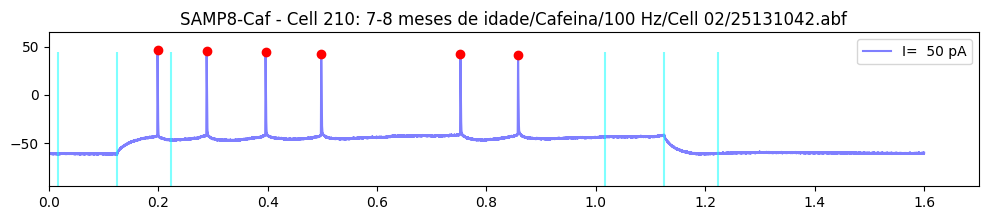

7-8 meses de idade/Cafeina/100 Hz/Cell 03/25203010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


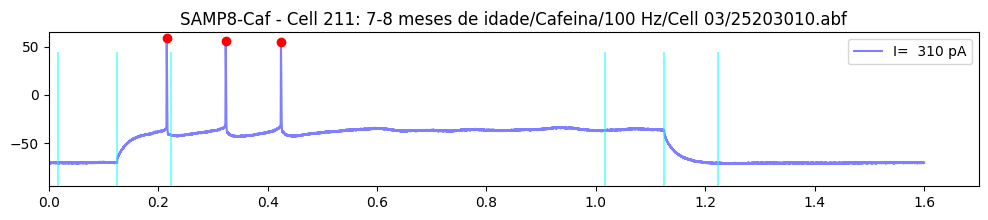

7-8 meses de idade/Cafeina/100 Hz/Cell 04/25206007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


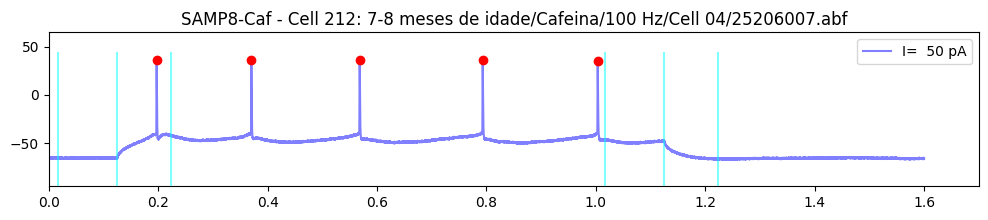

7-8 meses de idade/Cafeina/100 Hz/Cell 05/25207030.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


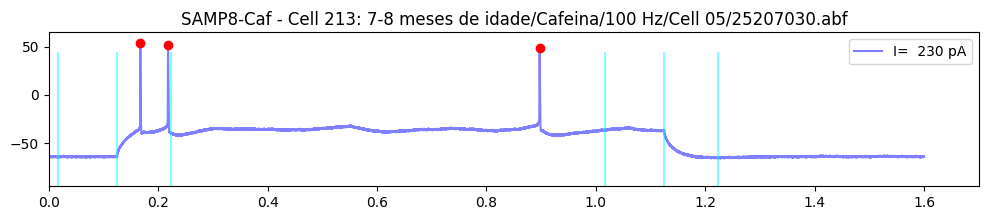

7-8 meses de idade/Cafeina/100 Hz/Cell 07/25213032.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


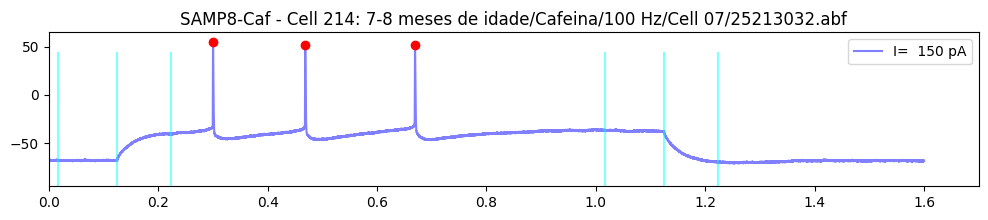

In [ ]:
############################################
# Pesquisando Celulas disponiveis
# Criar Lists com dados de Todas Células
# Salva um excel file no mesma pasta da célula
############################################

# Definir os folders para analises

fldrs = ['7-8 meses de idade/','7-8 meses de idade/Cafeina/','50-70 dias de idade SAMP-8 controle/']

# Definir nome do protocolo de interesse
protocolo = "Long"

times = []
voltages = []
I = []
cellnames = []
groupnames = []
subgroup = []
filenames = []

ListaPaTCH = []

# if peak_count >= 3 and peak_count <= 30 and I <= 270:
# 38, 67, 53

cellnumber = 0
for filename in ListaFiles:

                firstREO = 0

                abf = pyabf.ABF(filename)
                fs = abf.dataRate

                if protocolo in abf.protocol and len(abf.sweepList) >= 19:

                    ############################################
                    # Save Data and plot
                    ############################################

                    print(filename, abf.protocol, abf.sweepList)
                    # print(abf)

                    cellnumber = cellnumber + 1
                    celname = 'Cell ' + str(cellnumber)


                    outlier = 1
                    for i in abf.sweepList: # GUI>> modf p dados do gui (muitos steps)

                        abf.setSweep(i, channel=0)
                        peaks, peaksV = find_peaks(abf.sweepY, height=0, distance=200) # V > 0 mV and ISI > 10 ms (at 20kHz)
                        peak_count = len(peaks)
                        if peak_count >= 3:
                          outlier = 0

                    for i in abf.sweepList[0:20]: # GUI>> modf p dados do gui (muitos steps)
                        abf.setSweep(i, channel=0)
                        peaks, peaksV = find_peaks(abf.sweepY, height=0, distance=200) # V > 0 mV and ISI > 10 ms (at 20kHz)
                        peak_count = len(peaks)
                        if peak_count > 30:
                          outlier = 1

                    if "7-8 meses de idade/HPC whole cell/SAMP-8/Cell 37/24618002.abf" == filename:
                        outlier = 1

                    if outlier == 0:

                        IpA = -110
                        plt.figure(figsize=(12, 2))
                        for i in abf.sweepList: # GUI>> modf p dados do gui (muitos steps)

                            abf.setSweep(i, channel=0)

                            peaks, peaksV = find_peaks(abf.sweepY, height=0, distance=200) # V > 0 mV and ISI > 10 ms (at 20kHz)
                            peak_count = len(peaks)

                            if peak_count >= 3 and firstREO == 0:

                              firstREO = 1

                              if '50-70 dias de idade SAMP-8 controle/' in filename:
                                gname = 'SAMP2'
                              elif '7-8 meses de idade/Cafeina/' in filename:
                                gname = 'SAMP8-Caf'
                              else:
                                gname = 'SAMP8'

                              I.append((-110+20*i + abf.sweepC))
                              times.append(abf.sweepX)
                              voltages.append(abf.sweepY)
                              cellnames.append(celname)
                              groupnames.append(gname)
                              filenames.append(filename)

                              plt.plot(abf.sweepX, abf.sweepY, alpha=.5, color='blue',
                                        label="I=  %.0f pA" % (IpA-20.0))
                              plt.plot(abf.sweepX[peaks], abf.sweepY[peaks], 'ro')
                              # b, a = signal.butter(4, 0.05, "low")
                              # current_filtered = signal.filtfilt(b, a, abf.sweepY, padlen=150)
                              # plt.plot(abf.sweepX, current_filtered, alpha=.5, color='r', linewidth=2.5,
                              #           label="I=  %.0f pA" % (IpA-20.0))
                              plt.legend()
                              plt.title(gname + " - " + celname + ": "+(filename))
                              # plt.ylim(min(abf.sweepY[50:150])-5.0,min(abf.sweepY[50:150])+95)
                              plt.xlim(0.0,1.7)
                              plt.ylim(-95.0,65)
                              plt.vlines(x=[0.0172, 0.125, 0.2234, 1.0172, 1.125, 1.2234], ymin=-95.0, ymax=45.0, color='cyan', alpha = 0.5)

                            IpA = IpA + 20.0
                        plt.show()


In [ ]:
allcells, allcont = np.unique(cellnames,return_counts = True)

In [ ]:
allcells, allcont

(array(['Cell 1', 'Cell 10', 'Cell 102', ..., 'Cell 94', 'Cell 95',
        'Cell 96'], dtype='<U8'),
 array([1, 1, 1, ..., 1, 1, 1]))

In [ ]:
allgroups, allcont = np.unique(groupnames,return_counts = True)

allgroups[0], allcont[0]/1, allgroups[1], allcont[1]/1, allgroups[2], allcont[2]/1

(np.str_('SAMP2'),
 np.float64(54.0),
 np.str_('SAMP8'),
 np.float64(66.0),
 np.str_('SAMP8-Caf'),
 np.float64(65.0))

In [ ]:
# all
# NCells_SAMP8 = 68
# NCells_SAMP8_Caf = 64
# NCells_SAMP2 = 49

# excluindo outliers
NCells_SAMP8 = 66
NCells_SAMP8_Caf = 65
NCells_SAMP2 = 54

In [ ]:
############################################
# Analise eFEL (do Blue Brain Project)
############################################
traces = []

for ii in range(0, len(voltages)):

    if len(voltages[ii])/20000 < 1.2:
      trace = {'T': 1000.0*times[ii], 'V': voltages[ii],
              'I': I[ii],
              'stim_start': [17.2], 'stim_end': [1017.2]} #0.0172, 0.125, 0.2234
      traces.append(trace)
    elif len(voltages[ii])/20000 < 1.55:
      trace = {'T': 1000.0*times[ii], 'V': voltages[ii],
              'I': I[ii],
              'stim_start': [223.4], 'stim_end': [1223.4]} #0.0172, 0.125, 0.2234
      traces.append(trace)
    else:
      trace = {'T': 1000.0*times[ii], 'V': voltages[ii],
              'I': I[ii],
              'stim_start': [125.0], 'stim_end': [1125.0]} #0.0172, 0.125, 0.2234
      traces.append(trace)

Lista_de_medidas = ['time_constant', 'voltage_base', 'steady_state_voltage_stimend', 'time_to_first_spike',  'time_to_second_spike',  'time_to_last_spike',
                    'Spikecount','mean_frequency', 'steady_state_voltage', 'minimum_voltage',
                                        'all_ISI_values', 'peak_time', 'peak_voltage', 'AP_amplitude', 'AP_duration', 'AP_begin_time', 'AP_begin_width', 'AP_duration_half_width',
                                        'min_AHP_values', 'AP_fall_time', 'AP_height', 'AP_rise_time', 'ADP_peak_amplitude', 'ADP_peak_values', 'AHP_depth', 'AHP_depth_abs',
                                        'AHP_depth_abs_slow', 'AHP_depth_from_peak', 'AHP_depth_slow', 'AHP_time_from_peak',
                                        'voltage_deflection', 'decay_time_constant_after_stim', 'ISI_CV', 'adaptation_index']

efel.set_setting("Threshold", 0.0)

feature_values = efel.get_feature_values(traces, Lista_de_medidas, raise_warnings=False);

In [ ]:
ii = 25
I[ii],times[ii],voltages[ii],cellnames[ii],groupnames[ii], feature_values[ii]

(array([70., 70., 70., ..., 70., 70., 70.]),
 array([0.    , 0.0001, 0.0001, ..., 1.5998, 1.5999, 1.5999]),
 array([-63.2324, -63.2629, -63.1409, ..., -62.4695, -62.5916, -62.439 ],
       dtype=float32),
 'Cell 29',
 'SAMP2',
 {'time_constant': None,
  'voltage_base': array([-62.7808]),
  'steady_state_voltage_stimend': array([-43.2949]),
  'time_to_first_spike': array([105.9]),
  'time_to_second_spike': array([294.5]),
  'time_to_last_spike': array([706.3]),
  'Spikecount': array([4]),
  'mean_frequency': array([5.6633]),
  'steady_state_voltage': array([-61.581]),
  'minimum_voltage': array([-62.6221]),
  'all_ISI_values': array([188.6, 205. , 206.8]),
  'peak_time': array([230.9, 419.5, 624.5, 831.3]),
  'peak_voltage': array([61.0352, 58.96  , 57.5256, 55.0537]),
  'AP_amplitude': array([100.8301,  97.3511,  96.7102,  92.1326]),
  'AP_duration': array([2.6, 2.6, 2.7, 2.7]),
  'AP_begin_time': array([230.4, 418.9, 623.8, 830.6]),
  'AP_begin_width': array([2.5, 2.5, 2.7, 2.6]),
  '

In [ ]:
import pandas as pd

# Set the columns of the output table
table = pd.DataFrame(columns=['cell',
                              'current_pA',
                              'group',
                              'path_to_abf',
                              'abf_filename'])

In [ ]:
medidas = ['peak_voltage', 'AP_amplitude', 'AP_duration', 'AP_begin_time', 'AP_begin_width', 'AP_duration_half_width',
                                            'min_AHP_values', 'AP_fall_time', 'AP_height', 'AP_rise_time', 'ADP_peak_amplitude',
           'ADP_peak_values', 'AHP_depth', 'AHP_depth_abs',
                                            'AHP_depth_abs_slow', 'AHP_depth_from_peak', 'AHP_depth_slow', 'AHP_time_from_peak',
           'Spikecount', 'mean_frequency', 'time_to_first_spike',  'time_to_second_spike',  'time_to_last_spike']


for ii in range(0, len(voltages)):
    length = len(table)

    table.loc[ii, 'cell'] = cellnames[ii]
    table.loc[ii, 'current_pA'] = I[ii][0]
    table.loc[ii, 'group'] =  groupnames[ii]
    table.loc[ii, 'path_to_abf'] = os.path.dirname(filenames[ii])
    table.loc[ii, 'abf_filename'] = os.path.basename(filenames[ii])

    if feature_values[ii]['Spikecount'][0] > 0:
      table.loc[ii, 'mean_frequency'] = float(feature_values[ii]['mean_frequency'][0])
      table.loc[ii, 'Spikecount'] = float(feature_values[ii]['Spikecount'][0])
    else:
      table.loc[ii, 'mean_frequency'] = 0.0
      table.loc[ii, 'Spikecount'] = 0.0

    for medida in medidas:

      try:
        table.loc[ii, medida] = feature_values[ii][medida][0:3].mean()
      except:
        print("ERROR",ii, cellnames[ii], medida, feature_values[ii][medida])

In [ ]:
table

,cell,current_pA,group,path_to_abf,abf_filename,mean_frequency,Spikecount,peak_voltage,AP_amplitude,AP_duration,...,ADP_peak_values,AHP_depth,AHP_depth_abs,AHP_depth_abs_slow,AHP_depth_from_peak,AHP_depth_slow,AHP_time_from_peak,time_to_first_spike,time_to_second_spike,time_to_last_spike
0,Cell 1,190.0,SAMP2,50-70 dias de idade SAMP-8 controle/HPC - CPT-...,24523000.abf,28.517110,3.0,42.266846,79.528809,2.000000,...,-40.435791,19.568549,-40.842692,-46.997070,83.109538,13.414171,1.733333,15.4,37.1,105.2
1,Cell 2,50.0,SAMP2,50-70 dias de idade SAMP-8 controle/HPC - CPT-...,24523015.abf,8.852915,7.0,46.946208,94.350179,2.000000,...,-49.987793,9.260390,-51.218669,-53.273519,98.164876,7.205539,2.200000,35.9,94.2,790.7
2,Cell 3,30.0,SAMP2,50-70 dias de idade SAMP-8 controle/HPC - CPT-...,24523018.abf,5.364807,5.0,45.552572,91.318766,1.933333,...,-51.015218,6.293403,-52.632650,-55.308024,98.185221,3.618028,2.266667,80.2,283.3,932.0
3,Cell 4,190.0,SAMP2,50-70 dias de idade SAMP-8 controle/HPC - CPT-...,24919011.abf,5.507366,4.0,46.264648,82.956950,2.400000,...,-43.853760,23.127238,-43.986003,-47.790527,90.250651,19.322713,5.633333,38.4,96.1,726.3
4,Cell 6,90.0,SAMP2,50-70 dias de idade SAMP-8 controle/HPC - CPT-...,24n21017.abf,3.849115,3.0,48.217773,86.547852,2.500000,...,-38.859049,23.399577,-40.425618,-47.088623,88.643392,16.736572,2.100000,266.8,529.2,779.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180,Cell 210,70.0,SAMP8-Caf,7-8 meses de idade/Cafeina/100 Hz/Cell 02,25131042.abf,8.188890,6.0,45.359294,86.547852,2.400000,...,-41.890462,19.208415,-42.195638,-46.956380,87.554932,14.447673,2.533333,73.6,163.3,732.7
181,Cell 211,330.0,SAMP8-Caf,7-8 meses de idade/Cafeina/100 Hz/Cell 03,25203010.abf,10.026738,3.0,56.182861,87.392171,2.300000,...,-37.394206,30.963216,-39.408366,-43.762207,95.591227,26.609375,2.500000,90.4,198.2,299.2
182,Cell 212,70.0,SAMP8-Caf,7-8 meses de idade/Cafeina/100 Hz/Cell 04,25206007.abf,5.693464,5.0,36.275228,75.266520,2.300000,...,-42.561849,21.158610,-44.606527,-50.374349,80.881755,15.390788,2.233333,72.0,245.1,878.2
183,Cell 213,250.0,SAMP8-Caf,7-8 meses de idade/Cafeina/100 Hz/Cell 05,25207030.abf,3.886010,3.0,51.015218,80.006917,2.366667,...,-37.302653,25.875977,-38.330078,-42.358398,89.345296,21.847656,2.200000,42.2,92.8,772.0


In [ ]:
medidas = ['peak_voltage', 'AP_amplitude', 'AP_duration', 'AP_begin_time', 'AP_begin_width', 'AP_duration_half_width',
                                            'min_AHP_values', 'AP_fall_time', 'AP_height', 'AP_rise_time', 'ADP_peak_amplitude', 'ADP_peak_values', 'AHP_depth', 'AHP_depth_abs',
                                            'AHP_depth_abs_slow', 'AHP_depth_from_peak', 'AHP_depth_slow', 'AHP_time_from_peak']

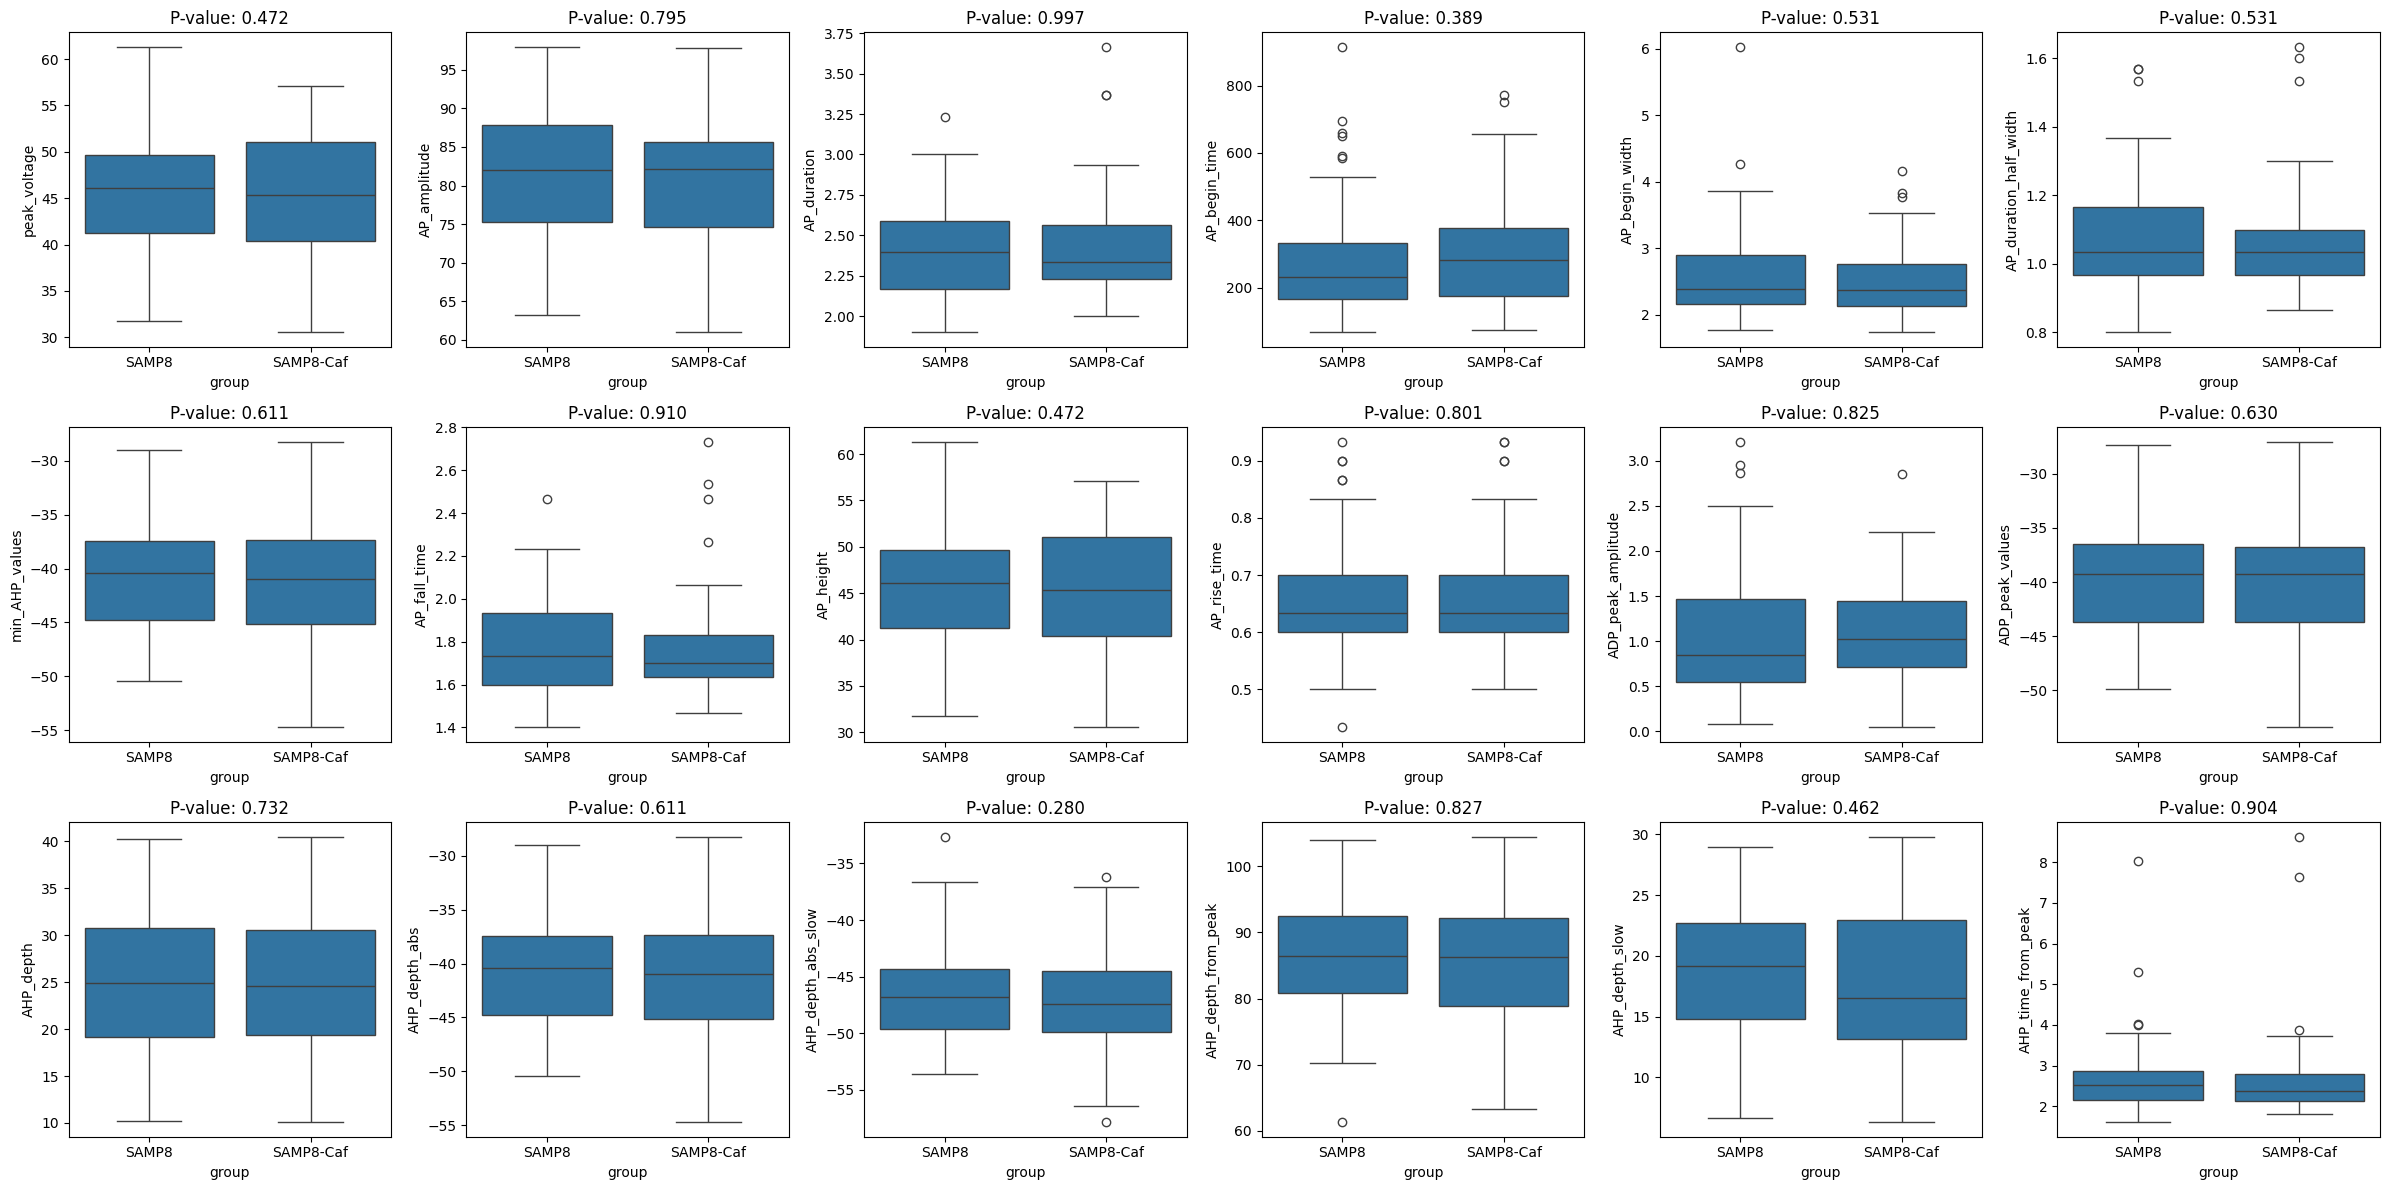

In [ ]:
fig, axes = plt.subplots(nrows=3, ncols=6, figsize=(24, 12))

data_filtered = table[table['group'].isin(['SAMP8','SAMP8-Caf'])]

for i, medida in enumerate(medidas):


    # Perform t-test
    control_data = data_filtered[data_filtered['group'] == 'SAMP8'][medida].astype(float) # Convert to numeric type
    Caf_data = data_filtered[data_filtered['group'] == 'SAMP8-Caf'][medida].astype(float) # Convert to numeric type
    t_stat, p_value = stats.ttest_ind(control_data, Caf_data)

    # print(f"T-statistic: {t_stat:.2f}")
    # print(f"P-value: {p_value:.3f}")

    # plt.title(f"Mean {medida}, P-value: {p_value:.3f}")
    # Create boxplot
    row = i // 6  # Calculate the row index
    col = i % 6   # Calculate the column index
    ax = axes[row, col]  # Access the correct Axes object using row and column indices
    ax.set_title(f"P-value: {p_value:.3f}")
    sns.boxplot(x='group', y=medida, data=data_filtered, ax = ax)

plt.tight_layout()
plt.show()

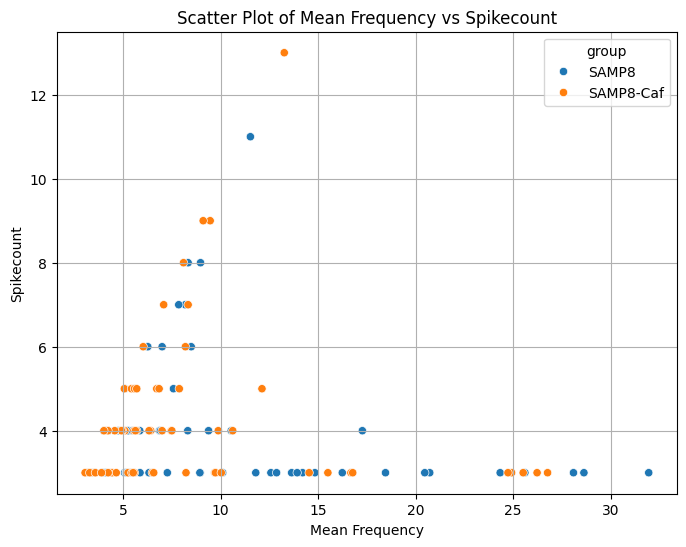

In [ ]:
#  'Spikecount', 'mean_frequency', 'time_to_first_spike',  'time_to_second_spike',  'time_to_last_spike'

plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_filtered, x='mean_frequency', y='Spikecount', hue='group')
plt.title('Scatter Plot of Mean Frequency vs Spikecount')
plt.xlabel('Mean Frequency')
plt.ylabel('Spikecount')
plt.grid(True)
plt.show()


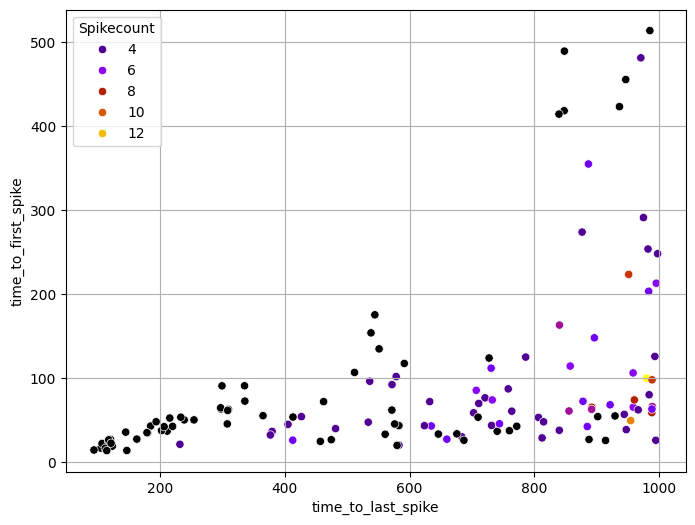

In [ ]:
#  'Spikecount', 'mean_frequency', 'time_to_first_spike',  'time_to_second_spike',  'time_to_last_spike'

aa = 'time_to_last_spike'
bb = 'time_to_first_spike'

plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_filtered, x=aa, y=bb, hue='Spikecount', palette='gnuplot')
plt.xlabel(aa)
plt.ylabel(bb)
plt.grid(True)
plt.show()


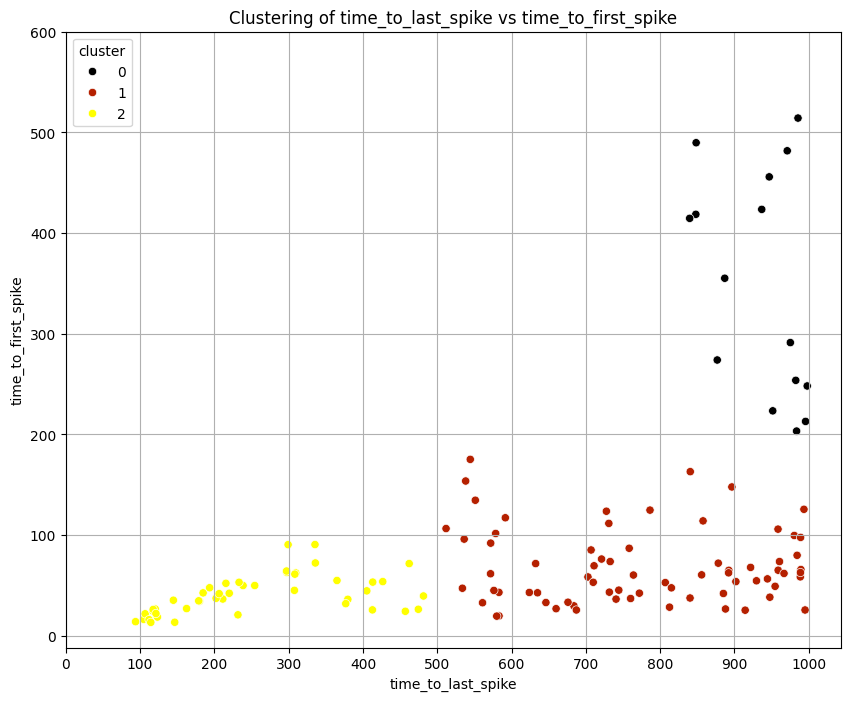

In [ ]:
# prompt: clustering the sccatter time_to_last_spike'  X 'time_to_first_spike'

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Prepare data for clustering
clustering_data = data_filtered[[aa, bb]].dropna() # Drop rows with NaN values
scaler = StandardScaler()
scaled_data = scaler.fit_transform(clustering_data)

# Determine optimal number of clusters (e.g., using Elbow method or visual inspection)
# For demonstration, let's assume 3 clusters
n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clustering_data['cluster'] = kmeans.fit_predict(scaled_data)

# Add cluster labels back to the original filtered data
data_filtered2 = data_filtered.merge(clustering_data[['cluster']], left_index=True, right_index=True, how='left')


# Plot the clustered data
plt.figure(figsize=(10, 8))
sns.scatterplot(data=data_filtered2, x=aa, y=bb, hue='cluster', palette='gnuplot')
plt.title(f'Clustering of {aa} vs {bb}')
plt.xlabel(aa)
plt.ylabel(bb)
plt.xticks(range(0,1100,100))
plt.yticks(range(0,700,100))
plt.grid(True)
plt.show()


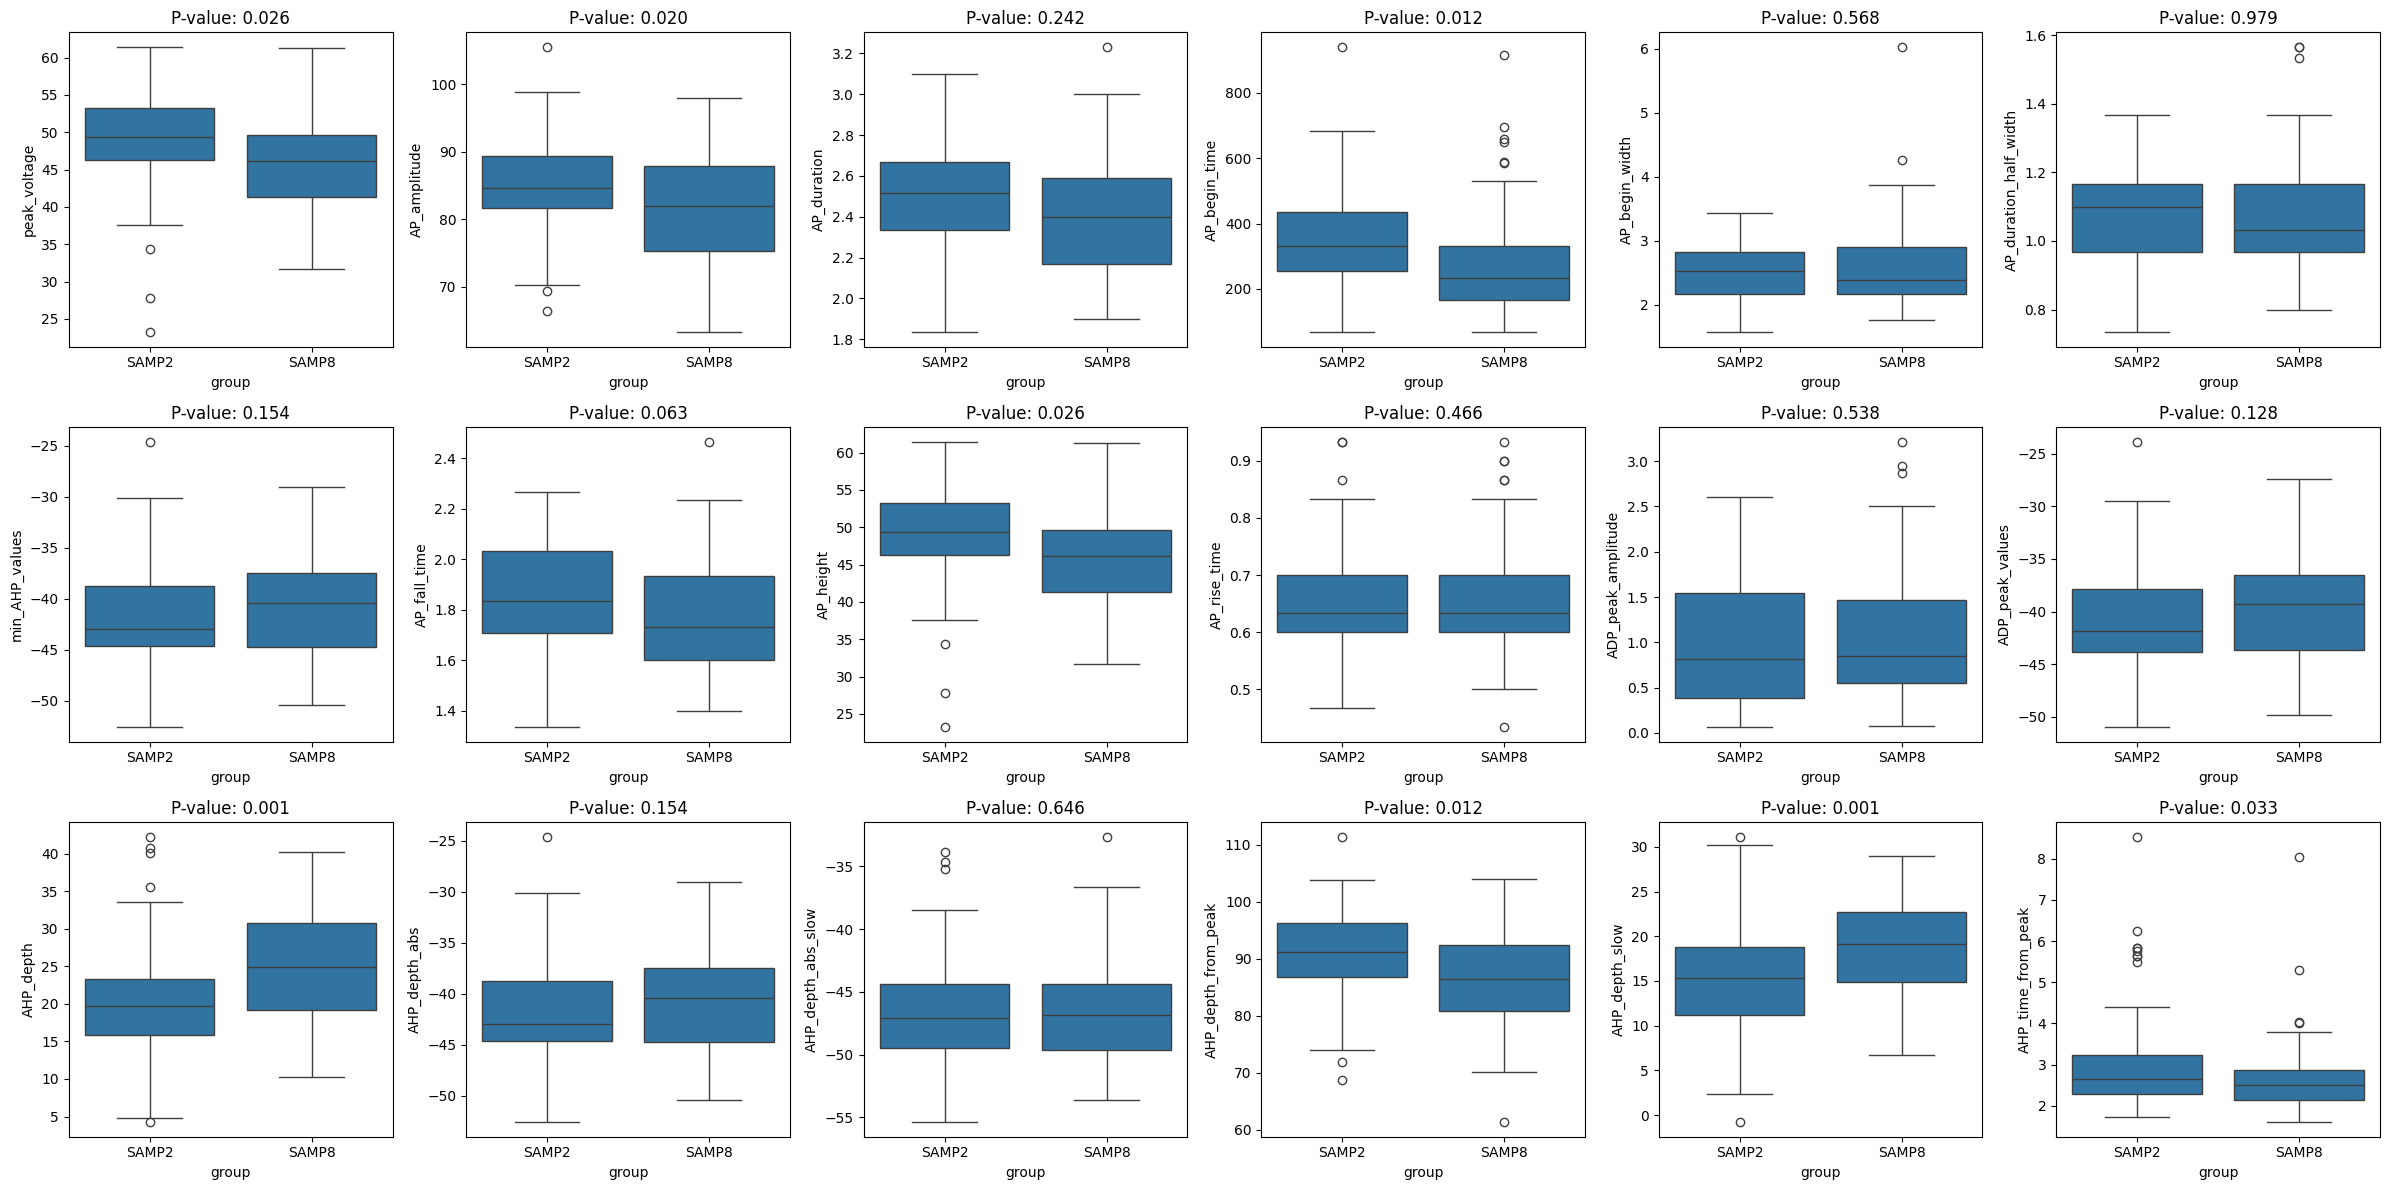

In [ ]:
fig, axes = plt.subplots(nrows=3, ncols=6, figsize=(24, 12))

data_filtered = table[table['group'].isin(['SAMP2','SAMP8'])]

for i, medida in enumerate(medidas):


    # Perform t-test
    control_data = data_filtered[data_filtered['group'] == 'SAMP2'][medida].astype(float) # Convert to numeric type
    Caf_data = data_filtered[data_filtered['group'] == 'SAMP8'][medida].astype(float) # Convert to numeric type
    t_stat, p_value = stats.ttest_ind(control_data, Caf_data)

    # print(f"T-statistic: {t_stat:.2f}")
    # print(f"P-value: {p_value:.3f}")

    # plt.title(f"Mean {medida}, P-value: {p_value:.3f}")
    # Create boxplot
    row = i // 6  # Calculate the row index
    col = i % 6   # Calculate the column index
    ax = axes[row, col]  # Access the correct Axes object using row and column indices
    ax.set_title(f"P-value: {p_value:.3f}")
    sns.boxplot(x='group', y=medida, data=data_filtered, ax = ax)

plt.tight_layout()
plt.show()

In [ ]:
SAMP8     = table[table["group"] == "SAMP8"].reset_index(drop=True)
SAMP2     = table[table["group"] == "SAMP2"].reset_index(drop=True)
SAMP8_Caf = table[table["group"] == "SAMP8-Caf"].reset_index(drop=True)

# SAMP8 = table.get(table["group"] == "SAMP8")
# SAMP2 = table.get(table["group"] == "SAMP2")
# SAMP8_Caf = table.get(table["group"] == "SAMP8-Caf")


In [ ]:
# ---------------------------------------  #
output_filename = 'Resultados_PAs_2025/SAMP8_ativas_filename.xlsx'

# Save DataFrame to an Excel file
SAMP8.to_excel(output_filename, sheet_name='all_currents', float_format="%.2f")

print(f"Saved SAMP8 data to {output_filename}")
# ---------------------------------------  #

output_filename = 'Resultados_PAs_2025/SAMP8_Caf_ativas_filename.xlsx'

# Save DataFrame to an Excel file
SAMP8_Caf.to_excel(output_filename, sheet_name='all_currents', float_format="%.2f")

print(f"Saved SAMP8_Caf data to {output_filename}")

# ---------------------------------------  #

output_filename = 'Resultados_PAs_2025/SAMP2_ativas_filename.xlsx'

# Save DataFrame to an Excel file
SAMP2.to_excel(output_filename, sheet_name='all_currents', float_format="%.2f")

print(f"Saved SAMP2 data to {output_filename}")


Saved SAMP8 data to Resultados_PAs_2025/SAMP8_ativas_filename.xlsx
Saved SAMP8_Caf data to Resultados_PAs_2025/SAMP8_Caf_ativas_filename.xlsx
Saved SAMP2 data to Resultados_PAs_2025/SAMP2_ativas_filename.xlsx


In [ ]:
# SAMP8.to_csv('Resultados_PAs_2025/SAMP8_ativas_3spikes.csv')
# SAMP2.to_csv('Resultados_PAs_2025/SAMP2_ativas_3spikes.csv')
# SAMP8_Caf.to_csv('Resultados_PAs_2025/SAMP8_Caf_ativas_3spikes.csv')

<Axes: xlabel='current_pA', ylabel='Count'>

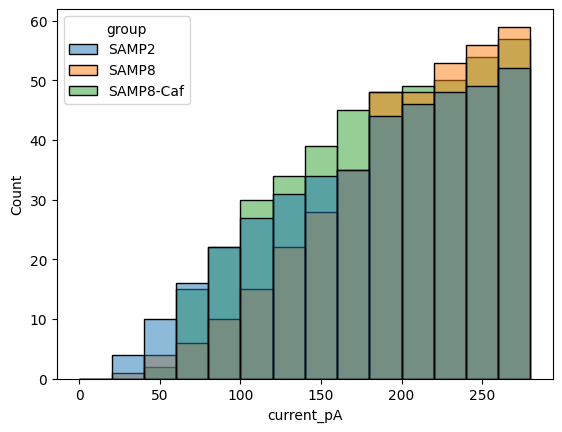

In [ ]:
sns.histplot(x='current_pA', data=table, bins=range(0,300,20), alpha = 0.5, cumulative=True, hue='group')

In [ ]:
table_reo = table[(table['current_pA'] >= 90) & (table['current_pA'] <= 170)]

<Axes: xlabel='current_pA', ylabel='Count'>

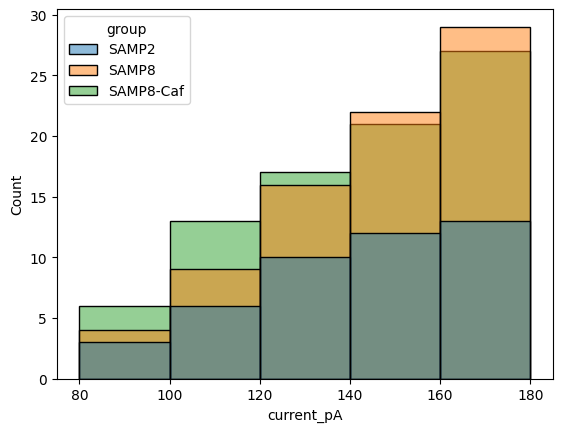

In [ ]:
sns.histplot(x='current_pA', data=table_reo, bins=range(80,200,20), alpha = 0.5, cumulative=True, hue='group')